# Spatial Big Data with DuckDB

用空间SQL查询全国两周微博，汇总位置网格、热相关讨论与城市间观测联系，用GeoPandas绘制静态对照图，用Lonboard与Plotly探索交互地图和有向联系网络。

<a id="course-toc"></a>
**目录**

- [1 把空间操作放进查询](#section-1)
- [2 连接DuckDB并加载Spatial](#section-2)
- [3 直接读Parquet：先过滤，再构造点](#section-3)
  - [3.1 矩形窗口：先限定研究范围](#section-3-1)
- [4 空间连接：哪些点在分析圆内？](#section-4)
  - [4.1 用同一个参考点重现04的范围查询](#section-4-1)
  - [4.2 查询计划：空间关系怎样被执行？](#section-4-2)
  - [4.3 行政边界：用空间SQL汇总市州](#section-4-3)
- [5 全国空间汇总：先计算，再传给绘图](#section-5)
  - [5.1 WKB → GeoPandas → Lonboard](#section-5-1)
- [6 全国空间分析：地图、讨论与分析单元](#section-6)
  - [6.1 网格面与比例圆点怎样选择？](#section-6-1)
  - [6.2 用SQL改变空间分辨率](#section-6-2)
  - [6.3 热力图：DuckDB直接连接Lonboard](#section-6-3)
  - [6.4 全国城市：哪里讨论得多，哪里讨论占比高？](#section-6-4)
  - [6.5 全国专题网格：数量多，还是占比高？](#section-6-5)
    - [6.5.1 全国概览：数量与比例](#section-6-5-1)
    - [6.5.2 四川及周边：放大同一批格子](#section-6-5-2)
  - [6.6 全国情感分析：模型分数在哪里不同？](#section-6-6)
  - [6.7 城市聚类画像：哪些城市的讨论结构相似？](#section-6-7)
    - [6.7.1 热图：同时比较五类讨论比例](#section-6-7-1)
    - [6.7.2 分组柱状图：同一类别中，哪些簇更突出？](#section-6-7-2)
    - [6.7.3 雷达图：观察每一簇的整体讨论画像](#section-6-7-3)
    - [6.7.4 城市地图与成员：把画像放回空间](#section-6-7-4)
  - [6.8 H3六边形网格：换一种空间汇总方式](#section-6-8)
  - [6.9 省、市与H3：同一批记录换一种分析单元](#section-6-9)
    - [6.9.1 交互地图：切换单元并放大比较](#section-6-9-1)
    - [6.9.2 哪些结果不变，哪些结果会改变？](#section-6-9-2)
- [7 城市间观测联系：从用户时序到有向网络（扩展）](#section-7)
  - [7.1 先核对观测时刻与城市](#section-7-1)
  - [7.2 LAG：找到同一用户的上一条观测](#section-7-2)
  - [7.3 构建城市节点与加权边](#section-7-3)
  - [7.4 节点的入向与出向联系](#section-7-4)
  - [7.5 ArcLayer：把城市联系画在高德底图上](#section-7-5)
  - [7.6 时间间隔阈值会改变哪些结果？](#section-7-6)
- [8 从查询到索引](#section-8)
  - [8.1 R-tree适合什么查询？](#section-8-1)
- [9 综合练习](#section-9)
  - [9.1 改变范围与分组](#section-9-1)
  - [9.2 让空间条件与文本条件一起工作](#section-9-2)
  - [9.3 开放问题：百万点一定要全画吗？](#section-9-3)

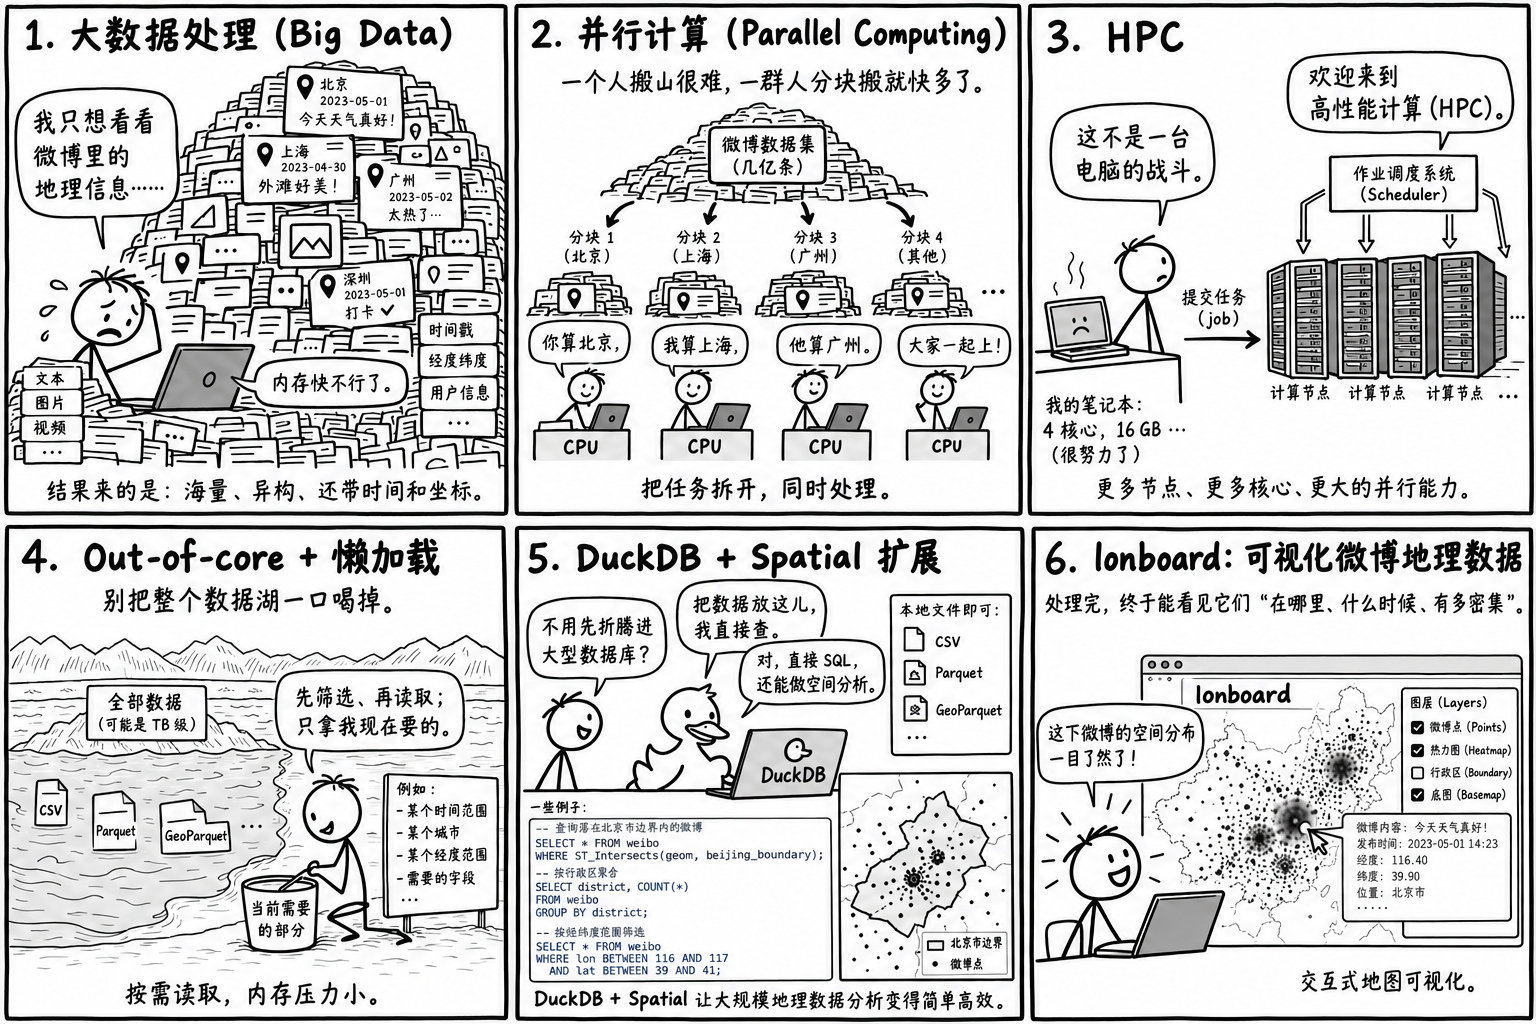

<a id="section-1"></a>
## 1 把空间操作放进查询 **[重点]**

本节读取全国2022年8月12—25日的同一份Parquet，把04的空间查询和05的讨论分析扩展到全国。

先学习筛选、空间连接与网格汇总（第1—5节），再比较全国讨论、情感、城市画像及分析单元（第6节）。第7节扩展到用户时序与城市网络，第8节介绍空间索引，第9节用综合练习核对理解。

首次运行请从头依次执行。标为“扩展”的内容可以选读；后续单元若使用它生成的表或变量，仍需先执行对应的准备代码。第7节的网络分析可以整节跳过，不影响第8—9节。

记住：这些是GCJ-02网格中心和离散观测。地图与同坐标行政面直接使用原数值；米制测量先近似转为WGS84再投影。城市间的相邻观测也不等于完整出行轨迹。

In [ ]:
# 保持整个tutorials文件夹结构；支持从项目根目录或tutorials目录启动。
from pathlib import Path
TUTORIAL_DIR = Path('.') if Path('data/posts_two_weeks.parquet').is_file() else Path('tutorials')
DATA = TUTORIAL_DIR / 'data/posts_two_weeks.parquet'
assert DATA.is_file(), '请先完整解压课堂资料，并用VS Code打开包含tutorials的文件夹'

<a id="section-2"></a>
## 2 连接DuckDB并加载Spatial **[重点]**

DuckDB负责读取、筛选和聚合；Spatial扩展增加点、线、面及空间关系函数。`INSTALL spatial`首次下载与DuckDB版本匹配的扩展，`LOAD spatial`在当前连接启用它。首次安装需要联网，之后使用本机缓存。

沿用03的JupySQL：`%%sql`交给同一个Python内核中的DuckDB连接执行。SQL单元设置为SQL高亮；不要把整个Notebook换成SQL Server内核。

连接中的表保存在内存里。重跑连接单元会沿用仍打开的连接；**重启内核或关闭连接后，旧的输出表格可能仍显示，但数据库中的表需要重新创建**。此时使用“全部运行”，或从头依次执行相关单元，不能只运行最后的地图。

In [ ]:
# 连接创建时才导入DuckDB；重跑本格时保留仍打开的连接和内存表。
import duckdb
try:
    # SELECT 1只返回数字1，用来检查连接是否仍可用，不读取微博表。
    con.execute('SELECT 1')
except (NameError, duckdb.ConnectionException):
    con = duckdb.connect()
%load_ext sql
# 将当前con交给JupySQL，避免SQL与Python使用不同的连接。
%sql con --alias spatial
# 文件路径进入SQL前使用正斜杠，并转义路径中的单引号。
PARQUET_PATH = DATA.as_posix().replace("'", "''")

In [ ]:
%%sql
-- 首次安装需要联网；扩展与当前DuckDB版本对应。
-- 目的：为当前DuckDB启用空间函数。INSTALL下载匹配版本的扩展，已有缓存时可复用。
INSTALL spatial;
-- LOAD把扩展加载到当前连接；新建连接后也需要执行。
LOAD spatial;
-- 验证一个点；ST_Point按经度、纬度顺序接收坐标。
-- ST_Point构造点；ST_AsText把几何转为可读的WKT文本；AS给结果列命名。
SELECT ST_AsText(ST_Point(104.07, 30.67)) AS example_point;

<a id="section-3"></a>
## 3 直接读Parquet：先过滤，再构造点 **[重点]**

Spatial扩展提供几何读取、构造和空间关系函数，常见函数使用`ST_`前缀，例如`ST_Point`与`ST_Intersects`。本教程使用DuckDB 1.4系列，可查阅[1.4版空间函数参考](https://duckdb.org/docs/1.4/core_extensions/spatial/functions)。

视图保存查询逻辑，不提前把整张全国表读成Pandas对象。只保留需要的列与可用位置记录，再用`ST_Point`构造几何。

`GEOMETRY`保存几何形状；在当前1.4版示范中，不能因为列名叫geom就认为它自动带有已核实的CRS。投影转换时仍明确写出源、目标坐标系。

保留`created_at`供后面的用户时序分析；`date`用于按日汇总，不能用它替代同一天内的发帖时刻。

In [ ]:
%%time
%%sql
-- 视图不复制整个文件；查询时才读取和计算。
-- 目的：给后续查询统一的数据入口，输出一条有效位置记录对应一行的located视图。
-- CREATE OR REPLACE表示同名对象存在时替换；VIEW保存查询定义，不复制整份数据。
CREATE OR REPLACE VIEW located AS
-- SELECT列出后面要用的字段；date::DATE把日期转成DATE类型，不保留时分秒。
SELECT post_id, user_id, created_at, date::DATE AS date, city_code, city, province_code,
       longitude_grid, latitude_grid,
       -- geom是几何列的别名，点的输入顺序为经度、纬度；GCJ-02数值不变。
       ST_Point(longitude_grid, latitude_grid) AS geom
-- FROM说明数据来源；read_parquet直接读文件，{{PARQUET_PATH}}由JupySQL取Python变量替换。
FROM read_parquet('{{PARQUET_PATH}}')
-- WHERE先筛记录：两个布尔质量标记都为真，才进入后续位置分析。
WHERE usable_text AND coordinate_valid;
-- 检查实际记录量，不预填一个“大数据”的固定门槛。
-- 结果核对：count(*)数记录行数，DISTINCT user_id先去重再数用户；同一用户可发多条。
SELECT count(*) AS located_records, count(DISTINCT user_id) AS users,
       -- min和max给出当前数据实际覆盖的最早、最晚日期。
       min(date) AS first_date, max(date) AS last_date FROM located;

<a id="section-3-1"></a>
### 3.1 矩形窗口：先限定研究范围

`ST_MakeEnvelope(最小经度, 最小纬度, 最大经度, 最大纬度)`构造矩形；`ST_Intersects`判断点是否与矩形相交，边界上的点也计入。

下面只是成都附近的教学矩形，不是成都市行政边界。用城市字段筛选与用几何范围筛选，是两个不同问题。

In [ ]:
%%sql
-- 目的：在一个经纬度矩形内统计城市标签；结果一行一个城市标签。
-- count(*)数帖子记录，count(DISTINCT user_id)数各组内不同用户，AS设置列名。
SELECT city, count(*) AS n_posts, count(DISTINCT user_id) AS n_users
-- 从前面已过滤质量的located视图读取点。
FROM located
-- ST_MakeEnvelope依次接收最小经度、最小纬度、最大经度、最大纬度。
-- ST_Intersects检查点是否与矩形相交，包括边界；这个矩形不是成都市行政边界。
WHERE ST_Intersects(geom, ST_MakeEnvelope(103.7, 30.3, 104.5, 31.0))
-- GROUP BY把同一city标签的记录放进同一组，再分别计数。
GROUP BY city
-- ORDER BY控制展示顺序；DESC表示按记录数从多到少排列。
ORDER BY n_posts DESC;

<a id="section-4"></a>
## 4 空间连接：哪些点在分析圆内？ **[重点]**

与04一样，GCJ-02原始坐标不能直接以EPSG:4326传给`ST_Transform`。先仅取成都不重复的网格中心，用`gcj2wgs`近似转换一次，再按原网格键连接回记录；这比对每条重复帖子转换更直观，也避免在SQL里写复杂坐标公式。

`geom`保留GCJ-02，供同坐标的矩形及行政边界查询；`geom_m`来自转换后的WGS84点，再投影到UTM 48N（EPSG:32648），用于距离。`always_xy := true`明确轴顺序。

物化的成都表留在当前内存数据库，关闭连接后释放；全国Parquet仍保留在磁盘。

In [ ]:
# 只转换成都的不同网格中心，不把全国帖子读入Pandas。
from xyconvert import gcj2wgs
# 先执行SQL，再用fetchdf把小结果转成Pandas表；不把全国明细传出数据库。
city_coords = con.execute("""
    -- DISTINCT只保留不同的经纬度组合，同一网格无论有多少帖子，都只转换一次坐标。
    SELECT DISTINCT longitude_grid, latitude_grid FROM located
    -- 51为四川、5101为成都，按原数据行政编码筛选，不靠文字城市名猜测。
    WHERE province_code='51' AND city_code='5101'
""").fetchdf()
xy_wgs = gcj2wgs(city_coords[['longitude_grid', 'latitude_grid']].to_numpy())
city_coords['wgs_lon'] = xy_wgs[:, 0]
city_coords['wgs_lat'] = xy_wgs[:, 1]
# register让SQL读取小型Python表，原始Parquet和GCJ-02字段保持不变。
con.register('city_coords', city_coords)
city_coords.head()

In [ ]:
%%sql
-- 目的：生成成都位置表；TABLE AS把查询结果保存到当前连接，供后续重复查询。
CREATE OR REPLACE TABLE city_points AS
-- p和c是两张表的短别名；p.字段表示取located中的原记录属性。
SELECT p.post_id, p.user_id, p.date, p.geom,
       -- 先用已经转换的WGS84数值构造点，再投影到EPSG:32648，得到单位为米的geom_m。
       ST_Transform(ST_Point(c.wgs_lon, c.wgs_lat), 'EPSG:4326', 'EPSG:32648',
                    -- always_xy := true明确输入按x、y，即经度、纬度排列，避免轴顺序混淆。
                    always_xy := true) AS geom_m
-- USING按两个表同名的经纬度列匹配，为每条帖子接上所在网格转换后的坐标。
-- 这里是按字段值匹配的属性连接；同一网格中的不同帖子仍分别保留。
FROM located p JOIN city_coords c USING (longitude_grid, latitude_grid)
-- 只保存原数据标记为成都的记录；geom保留GCJ-02，geom_m供米制度量。
WHERE p.province_code = '51' AND p.city_code = '5101';
-- geom是GCJ-02；geom_m是经过近似转换与投影的米制坐标。
-- 输出前三条几何作检查；LIMIT 3只限制展示，不会删掉city_points的其他行。
SELECT ST_AsText(geom) AS gcj02_lon_lat, ST_AsText(geom_m) AS meters FROM city_points LIMIT 3;

<a id="section-4-1"></a>
### 4.1 用同一个参考点重现04的范围查询

用成都记录的投影坐标中位数作为参考点，生成3公里和5公里两个教学分析圆。它们不是实际设施覆盖区；两个圆相互包含，所以同一条记录可以匹配两行范围。

SQL中的`LEFT JOIN ... ON ST_Intersects(...)`对应GeoPandas按空间关系连接。`count(p.post_id)`只计实际匹配记录；不能用`count(*)`把空匹配也算作一条。

In [ ]:
%%sql
-- 目的：用成都样本构造一个参考中心，再统计3公里和5公里范围内的记录。
CREATE OR REPLACE TABLE analysis_center AS
-- ST_X/ST_Y分别取米制横、纵坐标，median取中位数，再组合成一个参考点。
-- 这是样本中心，不是官方城市中心；不按用户去重或加权。
SELECT ST_Point(median(ST_X(geom_m)), median(ST_Y(geom_m))) AS geom FROM city_points;
-- zones保存两个分析圆：一行一个半径，后面可以同时连接位置记录。
CREATE OR REPLACE TABLE zones AS
-- ST_Buffer以米制参考点生成缓冲面；radius_m单位为米，16控制圆弧近似精细程度。
SELECT radius_m, ST_Buffer(geom, radius_m, 16) AS geom
-- VALUES建立只有3000、5000两行的小表；AS radii(radius_m)给表和列命名。
-- CROSS JOIN两两组合，一个参考点与两个半径得到两个缓冲区。
FROM analysis_center CROSS JOIN (VALUES (3000), (5000)) AS radii(radius_m);
-- 两个圆独立统计，不能将它们相加当作去重总量。
-- count(p.post_id)只数匹配到的帖子；LEFT JOIN未匹配的占位行不会被计为1条。
-- count(DISTINCT p.user_id)在每个圆内去重用户，两个圆可能包含同一帖子和用户。
SELECT z.radius_m, count(p.post_id) AS n_posts, count(DISTINCT p.user_id) AS n_users
-- LEFT JOIN保留每个分析圆；ON用ST_Intersects判断哪些米制位置落在圆内或边界上。
FROM zones z LEFT JOIN city_points p ON ST_Intersects(p.geom_m, z.geom)
-- 每个半径单独统计并按大小排序；3公里圆包含在5公里圆内，两行不能相加作去重总量。
GROUP BY z.radius_m ORDER BY z.radius_m;

<a id="section-4-2"></a>
### 4.2 查询计划：空间关系怎样被执行？

03中，查询计划解释读哪些列、怎样过滤和分组；这里检查空间连接怎样执行。`EXPLAIN ANALYZE`会真实运行查询，并返回计划和执行统计。

从下往上读：两张表分别输入多少行，空间连接输出多少匹配行，最后分组得到几行。当前1.4环境可能将空间连接显示为`EXTENSION`，其中列出`Join Type`和`ST_Intersects`条件；其他版本可能直接显示`SPATIAL_JOIN`。不能仅凭写了空间函数就宣称用上空间索引，也不能把这一次的秒数当作硬件无关的性能保证。

In [ ]:
%%sql spatial_plan <<
-- 目的：观察刚才空间连接的执行方式和耗时；EXPLAIN ANALYZE会实际运行下面的查询。
-- 单元首行的spatial_plan <<把返回的计划表存进Python变量，下一格可完整打印。
EXPLAIN ANALYZE
-- 查询内容仍是各半径内的帖子计数，便于把计划与上一格的分析对应起来。
SELECT z.radius_m, count(p.post_id) AS n_posts
-- 从缓冲区出发做空间连接，再按半径汇总；计划可用于查看实际处理的行数与连接算子。
FROM zones z LEFT JOIN city_points p ON ST_Intersects(p.geom_m, z.geom)
GROUP BY z.radius_m;

In [ ]:
# 查询计划是长文本，取第一行第二列，完整打印，避免表格截断。
print(spatial_plan[0][1])

<a id="section-4-3"></a>
### 4.3 行政边界：用空间SQL汇总市州 **[重点]**

`ST_Read`把GeoJSON边界读成表，`geom`保留文件中的GCJ-02数值。此处点与面同坐标，可以直接做空间关系判断，不需要先投影。

下面按网格中心落入的市州统计，区别于按源`city_code`分组。粗网格中心可能跨边界，边界也是参考快照，因此两种结果不必完全一样；不据此覆盖源城市字段。`ST_Intersects`包括边界，恰在公共边界的点可能匹配两城，不能未经检查将各城数相加。

In [ ]:
# 边界文件与微博数据统一用相对路径，进入SQL前处理路径字符。
BOUNDARY_PATH = (TUTORIAL_DIR / 'data/spatial/boundaries/sichuan_cities_gcj02.geojson').as_posix().replace("'", "''")

每条完整SQL语句用分号`;`结束。同一个`%%sql`单元可以按顺序执行多条语句，例如先创建汇总表，再查询该表。

In [ ]:
%%sql
-- 目的：先读四川市州边界，再把位置记录按空间关系连接到市州，输出一行一个市州。
CREATE OR REPLACE TABLE admin_cities AS
-- 修复部分边界的自相交，提取面部分；这不改变GCJ-02坐标体系。
-- ST_MakeValid修复无效几何；ST_CollectionExtract的3表示取面部分，保留边界编码和名称。
SELECT adcode, name, ST_CollectionExtract(ST_MakeValid(geom), 3) AS geom
-- ST_Read读取空间文件；{{BOUNDARY_PATH}}来自上一格设置的相对文件路径。
FROM ST_Read('{{BOUNDARY_PATH}}');
-- 只读取四川位置记录，再与21个市州面连接；左右都是GCJ-02。
-- a代表行政区，p代表帖子；分别计算每个区内的记录数和去重用户数。
SELECT a.adcode, a.name, count(p.post_id) AS n_posts,
       count(DISTINCT p.user_id) AS n_users
FROM admin_cities a
-- 括号中是子查询：先从located筛四川记录，只保留连接和计数需要的三列。
-- LEFT JOIN保留全部市州，没有匹配记录的市州也会出现在结果里。
LEFT JOIN (SELECT post_id, user_id, geom FROM located WHERE province_code='51') p
-- ON是连接条件：GCJ-02位置点与同坐标体系的市州面相交，包括面边界。
ON ST_Intersects(p.geom, a.geom)
-- 按区划编码和名称分组，记录数降序展示；边界或面重叠可能使一条记录匹配多个区。
GROUP BY a.adcode, a.name ORDER BY n_posts DESC;

<a id="section-5"></a>
## 5 全国空间汇总：先计算，再传给绘图 **[重点]**

全国数据有上百万行，但同一个粗网格可能重复出现。先按网格汇总，得到每格记录数和用户数，再传给绘图。这样传输的行更少，也不会把正文和匿名用户ID发送到地图前端。

`%%time`放在`%%sql`前面可统计整个单元的墙钟时间。它包括查询和结果处理，不能直接当成纯扫描时间。

In [ ]:
%%time
%%sql
-- 目的：把全国明细压缩成网格汇总，一行对应一个原始0.02度网格中心。
CREATE OR REPLACE TABLE grid_counts AS
-- 保留网格中心，同时统计每格记录数和格内去重用户数。
SELECT longitude_grid, latitude_grid, count(*) AS n_posts,
       count(DISTINCT user_id) AS n_users
-- 只使用located中的有效位置记录，不把无效位置纳入网格总量。
FROM located
-- 经度和纬度共同决定一个网格；不能只按其中一列分组。
GROUP BY longitude_grid, latitude_grid;
-- 括号内标量子查询给出聚合前总行数；外层count(*)给出聚合后网格数。
-- sum(n_posts)把各格记录数相加，应还原原始行数；各格去重用户数则不能这样相加。
SELECT (SELECT count(*) FROM located) AS original_rows,
       count(*) AS grid_rows, sum(n_posts) AS reconstructed_rows FROM grid_counts;

<a id="section-5-1"></a>
### 5.1 WKB → GeoPandas → Lonboard

WKB是几何的二进制表示，用来在数据库和Python间传递几何。只取四川附近的聚合网格，在SQL中重建网格面，转换成GeoDataFrame，再用Lonboard画数量。

这一步展示几何如何从DuckDB传到Python表，再交给绘图库；返回的只是聚合结果，不是全国帖子明细。6.3还会使用`from_duckdb()`直接把查询交给Lonboard。矩形范围依旧是分析窗口，不是省界。

`PolygonLayer`绘制网格面，`Map`组合图层与高德底图。四种颜色由浅到深表示1条、2—5条、6—20条、21条及以上，悬停查看数量。GCJ-02原始坐标直接显示，不重复偏移。

在 VS Code 中选择课程 Python 内核，并从上到下运行代码。地图单元的最后一行直接写地图对象，即可拖动、缩放和悬停查看网格信息；高德底图需要联网。仅打开 Notebook 时，保存的交互输出不一定恢复显示，请实际运行地图单元。

In [ ]:
# 只取区域汇总；直接在SQL中把原0.02度网格中心构造成面。
summary = con.execute("""
    -- 目的：只读取指定矩形内的网格汇总，并为每格构造一个面。
    SELECT longitude_grid, latitude_grid, n_posts, n_users,
           -- ST_MakeEnvelope以中心向四周各扩0.01度，重建0.02度方格；不是计算米制缓冲区。
           -- ST_AsWKB把网格面编码成二进制，方便下面用GeoPandas读取。
           ST_AsWKB(ST_MakeEnvelope(longitude_grid-0.01, latitude_grid-0.01,
                                   longitude_grid+0.01, latitude_grid+0.01)) AS wkb
    -- 经度97—109、纬度26—35是矩形显示窗口；BETWEEN包含两端，不是精确省界裁剪。
    FROM grid_counts WHERE longitude_grid BETWEEN 97 AND 109 AND latitude_grid BETWEEN 26 AND 35
""").fetchdf()
# 数据库BLOB转bytes，再用GeoPandas读取WKB；这里的几何已经是网格面。
import geopandas as gpd
geometry = gpd.GeoSeries.from_wkb([bytes(value) for value in summary.pop('wkb')], crs=None)
grid_geo = gpd.GeoDataFrame(summary, geometry=geometry)
grid_geo.head()

In [ ]:
# 第一次画地图时再导入Lonboard；GeoPandas负责数据，Lonboard负责显示。
from lonboard import Map, PolygonLayer, BitmapTileLayer
import pandas as pd
import numpy as np
# 四种RGBA颜色的最后一项为透明度；后面的全国地图复用相同色阶。
palette = np.array([[255, 237, 160, 170], [254, 178, 76, 180],
                    [240, 59, 32, 195], [189, 0, 38, 210]], dtype=np.uint8)
# 直接向高德请求栅格瓦片；style=7是该瓦片接口的样式参数。
AMAP_TILE_URL = 'https://wprd01.is.autonavi.com/appmaptile?lang=zh_cn&size=1&scale=1&style=7&x={x}&y={y}&z={z}'
gaode_tiles = BitmapTileLayer(data=AMAP_TILE_URL,tile_size=256,
    min_zoom=3,max_zoom=18,pickable=False)  # 放在数据图层下方，不响应悬停。

In [ ]:
# 先显示区域汇总，下一节用同样的方法扩展到全国网格。
region_group = pd.cut(grid_geo['n_posts'], [0, 1, 5, 20, float('inf')], labels=False)
region_layer = PolygonLayer.from_geopandas(grid_geo,
    get_fill_color=palette[region_group.to_numpy()], filled=True, stroked=False)  # 只填色，不画格网描边。
region_map = Map([gaode_tiles, region_layer], basemap=None, height=520, use_device_pixels=1,
    custom_attribution='高德地图 · 区域汇总 · GCJ-02 · 0.02°网格',
    view_state={'longitude': 104.0, 'latitude': 30.5, 'zoom': 6})
region_map  # 最后一行直接显示 Lonboard 交互地图。

<a id="section-6"></a>
## 6 全国空间分析：地图、讨论与分析单元 **[重点]**

本章先比较格网、比例圆与热力图，再沿用05的词表分析全国城市与网格中的讨论和情感，最后用H3比较空间分辨率及分析单元。

静态图用于固定范围的并排比较，省界和省名帮助定位；交互图用于缩放、悬停和切换单元。6.4、6.6与6.7的城市地图以及6.5的数量／比例对照使用静态图；热力图、6.8的H3地图与6.9的分析单元对照保留交互。

DuckDB已经把百万条记录汇总到较少的格子。现在用Lonboard的`PolygonLayer`以填色面展示真实格子范围，用分级颜色表示每格记录数；不绘制格网描边，悬停查看数量。

使用`BitmapTileLayer`直接读取高德栅格瓦片，把它放在数据图层列表的第一位，后面的网格与边界绘制在上方。`basemap=None`关闭额外的MapLibre底图；高德瓦片仍作为第一个图层显示，需联网。地图保留“高德地图”署名。

颜色由浅到深分别表示1条、2—5条、6—20条、21条及以上。这里是**每格数量**，不是人口密度或热浪危险度；空间分辨率仍是0.02度。[Lonboard瓦片图层接口](https://developmentseed.org/lonboard/latest/api/layers/bitmap-tile-layer/)

**坐标处理遵循“原坐标显示、转换后测量”。** 微博网格与DataV边界都是GCJ-02，直接叠加高德底图，不重复调用`wgs2gcj`。GCJ-02没有这里可直接使用的EPSG编号，原始显示几何的CRS留空，不能通过`set_crs(4326)`把它变成WGS84。

需要测量时，先用`gcj2wgs`近似转换GCJ-02数值，再声明EPSG:4326，最后投影到成都附近适用的EPSG:32648。近似转换和0.02°网格化都限制精度；它们不会恢复真实位置。Lonboard可能提示原始几何没有CRS，这是本课明确保留GCJ-02坐标的结果。

In [ ]:
# 从数据库只取全国网格汇总，不包含正文和用户ID。
# SELECT列出全国网格中心和两种计数；FROM grid_counts读取聚合表，fetchdf转换成Pandas表。
national = con.execute('SELECT longitude_grid, latitude_grid, n_posts, n_users FROM grid_counts').fetchdf()
import shapely
# 与04相同，按中心±0.01度重建原网格面。
national_geo = gpd.GeoDataFrame(national, geometry=shapely.box(
    national['longitude_grid']-0.01, national['latitude_grid']-0.01,
    national['longitude_grid']+0.01, national['latitude_grid']+0.01), crs=None)
# 原网格面已经是GCJ-02，直接显示，不再进行WGS84→GCJ-02偏移。
map_cells = national_geo.copy()
print('浏览器接收的聚合网格数：', len(national_geo))
national_geo[['n_posts', 'n_users']].head()

In [ ]:
# 全国地图沿用上一节的颜色与底图，不改变数量分级口径。
count_group = pd.cut(map_cells['n_posts'], [0, 1, 5, 20, float('inf')], labels=False)
# 显示副本没有正式EPSG，Lonboard会提示无CRS；这里已明确使用GCJ-02数值配对高德瓦片。
grid_layer = PolygonLayer.from_geopandas(map_cells, get_fill_color=palette[count_group.to_numpy()], filled=True, stroked=False)  # 行政区轮廓另由下方图层绘制。
# 行政区面只画轮廓，与GCJ-02网格共用同一高德底图。
admin_boundaries = gpd.read_file(TUTORIAL_DIR / 'data/spatial/boundaries/sichuan_cities_gcj02.geojson').set_crs(None, allow_override=True)
admin_boundaries = admin_boundaries[['adcode', 'name', 'geometry']]
admin_boundaries.geometry = admin_boundaries.geometry.make_valid(method='structure', keep_collapsed=False)
# boundary提取面边界为线；PathLayer只画轮廓，不用面填色遮挡网格。
from lonboard import PathLayer
admin_lines = admin_boundaries.copy()
admin_lines.geometry = admin_boundaries.geometry.boundary
boundary_layer = PathLayer.from_geopandas(admin_lines,
    get_color=[20, 50, 80, 220], get_width=1, width_min_pixels=1)
big_map = Map([gaode_tiles, grid_layer, boundary_layer], basemap=None, height=520, use_device_pixels=1,
    custom_attribution='高德地图 · GCJ-02 · 0.02°网格',
    view_state={'longitude': 104.07, 'latitude': 30.67, 'zoom': 9})
big_map  # 最后一行直接显示 Lonboard 交互地图。

<a id="section-6-1"></a>
### 6.1 网格面与比例圆点怎样选择？ **[扩展]**

网格面能展示分辨率与覆盖范围；比例圆点适合突出数量差异，但圆的大小不代表地面占用范围。点放在格子中心，一格一个点，不随机生成假位置。

若希望圆面积约与数量成正比，半径要与数量的平方根成正比。下面限制最小、最大屏幕尺寸以便阅读，限制生效后不再严格面积成比例。课堂可只选一种地图展示。

In [ ]:
# 在同一GCJ-02显示副本上取几何中心，保持统计值不变。
from lonboard import ScatterplotLayer
bubble_cells = map_cells.copy()
bubble_cells.geometry = shapely.centroid(map_cells.geometry.array)
bubble = ScatterplotLayer.from_geopandas(bubble_cells,
    get_radius=np.sqrt(bubble_cells['n_posts'].to_numpy())*300,
    radius_min_pixels=2, radius_max_pixels=18, get_fill_color=[38, 124, 135, 170])
point_map = Map([gaode_tiles, bubble, boundary_layer], basemap=None, height=520, use_device_pixels=1,
    custom_attribution='高德地图 · 一格一点 · 数量比例圆',
    view_state={'longitude': 104.07, 'latitude': 30.67, 'zoom': 9})
point_map  # 最后一行直接显示 Lonboard 交互地图。

<a id="section-6-2"></a>
### 6.2 用SQL改变空间分辨率 **[扩展]**

重做04的0.04度合并。保持原细格边界对齐，回到`located`中的原始记录重新计用户数；不能将各细格用户数直接相加。对照两种尺度的格子数、记录总数与每格最大值。

In [ ]:
%%time
%%sql
-- 目的：直接从记录明细重新按0.04度粗格分组，比较空间分辨率变化后的网格数。
CREATE OR REPLACE TABLE coarse_004 AS
-- 坐标先平移0.01度以对齐细格边界，再除以0.04并用floor向下取整，得到粗格横向编号ix。
SELECT floor((longitude_grid+0.01)/0.04)::INTEGER AS ix,
       -- 同样计算纵向编号iy；::INTEGER把格号转成整数，ix和iy共同标识一个粗格。
       floor((latitude_grid+0.01)/0.04)::INTEGER AS iy,
       -- 在粗格内重新去重用户；跨细格出现的同一用户，在同一粗格中只计一次。
       count(*) AS n_posts, count(DISTINCT user_id) AS n_users
-- 从明细按粗格号聚合，因此记录不会因合并网格而重复或丢失。
FROM located GROUP BY ix, iy;
-- 分辨率改变，观测总量不应凭空增加或减少。
-- 上行概括原网格：常量文本标注分辨率，count数格子，sum数记录，max取最繁忙格的记录数。
SELECT '0.02°' AS resolution, count(*) AS cells, sum(n_posts) AS total_posts, max(n_posts) AS max_per_cell FROM grid_counts
-- UNION ALL把两行统计上下拼接，不额外去重；两行是两种分辨率，不能合计为总样本量。
UNION ALL
SELECT '0.04°', count(*), sum(n_posts), max(n_posts) FROM coarse_004;

<a id="section-6-3"></a>
### 6.3 热力图：DuckDB直接连接Lonboard **[扩展]**

网格图以各格的填色表示数量，比例圆点用大小显示每格数量；**空间热力图（heatmap）**则把邻近位置的贡献平滑叠加，方便观察发帖位置集中在哪里。这里的“热”指记录集中程度，不是气温，也不是05中的热相关文本标签。

继续使用全国全部有效位置记录，不另筛高温词。DuckDB已经把明细汇总成`grid_counts`：**一行一个0.02°网格中心，`n_posts`是该格记录数**。下面把中心构造成点，再将这个小结果直接交给Lonboard，省去WKB转GeoPandas的中间步骤。原始微博正文与用户ID仍留在数据库中。

不能把每个网格都当成一条帖子：一个格子有100条记录，另一个只有1条，贡献应当不同。因此使用`n_posts`作为权重，并按`SUM`叠加；这对应每条有效位置记录贡献一次，不是每位用户贡献一次。


In [ ]:
%%time
%%sql spatial
-- ST_Point以经度、纬度构造网格中心点；坐标值仍为GCJ-02，不在这里转换。
-- 目的：从网格计数生成带权重点表，一行仍是一个格子，供后面的HeatmapLayer直接读取。
CREATE OR REPLACE TABLE heatmap_points AS
-- 保留中心数值和n_posts；n_posts是热力图权重，不是把每个网格当成1条帖子。
SELECT longitude_grid, latitude_grid, n_posts,
       ST_Point(longitude_grid, latitude_grid) AS geom
-- 只读已汇总的小表，不重新把全国微博明细传到浏览器。
FROM grid_counts;
-- 点数应等于网格数，权重合计应等于聚合前的有效位置记录数。
-- 结果检查：count(*)数绘图点，sum(n_posts)数这些点代表的原始记录，max查看最大权重。
SELECT count(*) AS map_points, sum(n_posts) AS represented_posts,
       max(n_posts) AS max_posts_per_grid
FROM heatmap_points;

In [ ]:
from lonboard import HeatmapLayer  # 将带权重的点平滑成热力图。

# con.sql返回查询关系；明确排序，使坐标与权重始终按同一顺序排列。
heat_query = con.sql("""
    -- 只选图层需要的权重与几何；不传正文、用户ID或其他明细字段。
    SELECT n_posts, geom FROM heatmap_points
    -- 按经纬度固定行顺序，后面提取的权重数组就能与同一查询的几何逐行对应。
    ORDER BY longitude_grid, latitude_grid
""")
# select只取权重列；fetchnumpy将这一列转换为NumPy数组。
heat_weights = heat_query.select('n_posts').fetchnumpy()['n_posts']

# from_duckdb直接读取几何查询；get_weight为每个网格设置记录数权重。
# crs=None保留已确认的GCJ-02数值，直接配对高德，不误标为EPSG:4326。
# aggregation='SUM'累加贡献；radius_pixels控制屏幕上的平滑半径。
heat_layer = HeatmapLayer.from_duckdb(heat_query, con=con, crs=None,
    get_weight=heat_weights, aggregation='SUM', radius_pixels=30)
print('传入地图的网格点数：', len(heat_weights), '；代表记录数：', int(heat_weights.sum()))

In [ ]:
# 叠加已有四川市州轮廓；初始视野定位成都及周边，可缩小地图观察全国。
heat_map = Map([gaode_tiles, heat_layer, boundary_layer], basemap=None, height=520,
    use_device_pixels=1,
    custom_attribution='高德地图 · GCJ-02 · 发帖记录加权热力图 · 屏幕半径30像素',
    view_state={'longitude': 104.07, 'latitude': 30.67, 'zoom': 7})
heat_map  # 最后一行直接显示交互地图，无需display或额外的HTML文件。

**怎样读这张图？**

- 颜色表示邻近网格记录的加权平滑强度，暖色较深的地方表示记录更集中。它不是每平方公里的记录数，也不能直接解释为人口密度、用户密度或热浪影响。
- `radius_pixels=30`的单位是**屏幕像素**。缩放地图后，同样30像素对应的地面距离会改变；把半径改成15或60并重跑本节地图，观察热点的分散与合并。它与05中投影后固定5公里带宽的KDE不同。
- 热力图帮助发现集中区，不能从颜色直接读出某一格的精确条数。需要核对数量时，回到SQL结果或前面的网格地图。比较不同时间或区域时，还应统一筛选口径、视野、缩放与图层参数，不能只比较颜色深浅。

DuckDB负责筛选、构造几何与计数；Lonboard负责在浏览器中平滑和绘图。计算在本机完成，无需MotherDuck账号；高德底图仍需联网。

[DuckDB与Lonboard热力图示例](https://motherduck.com/blog/getting-started-gis-duckdb/) · [HeatmapLayer参数](https://developmentseed.org/lonboard/latest/api/layers/heatmap-layer/) · [DuckDB直接连接Lonboard](https://developmentseed.org/lonboard/latest/ecosystem/duckdb/)


<a id="section-6-4"></a>
### 6.4 全国城市：哪里讨论得多，哪里讨论占比高？ **[扩展]**

沿用05的热相关词表与五类讨论词表，把筛选规则放进DuckDB。
这次用**全国行政区面**绘制分级色彩地图，先回答“帖子落在哪个城市范围”，再统计讨论比例。

源数据的城市标签含一些旧编码，不能直接套到另一版本的边界上。
因此本节将原始0.02°网格中心与缓存边界相交，只保留**位置有效、且唯一匹配到一个城市单元**的记录。
同一网格只匹配一次边界，再把归属连接回帖子。这与05按源城市标签分组的口径不同，不能直接把两张城市表逐行视为相同统计。
这里的“城市单元”还包括直辖市整体、台湾及港澳整体，以及按源编码前缀合组的省直辖县级单元。

- **热相关帖子**：命中任一热相关词。
- **某类相关帖子**：既命中热相关词，又命中该类词。例如只有“空调”而没有热相关词，不计入基础设施类。
- 所有比例都来自上述成功归属的有效观测；未命中或无法归属的数量需要分开理解。

| 指标 | 分子 / 分母 | 回答的问题 |
|---|---|---|
| 热相关帖子数 `n_heat` | 本城市热相关记录数 | 在有效观测中讨论了多少条？ |
| 热相关比例 `heat_share` | 热相关记录数 / 本城市全部有效观测数 | 这类讨论在当地采集记录中占多大比例？ |
| 类别占比 `topic_share` | 某类相关记录数 / 本城市热相关记录数 | 热相关讨论中，这一类别占多大比例？ |

**为什么不用全文检索？** 固定词表计数用`regexp_matches(text,'词1|词2')`判断是否包含任一词，
便于与05核对标签规则。[DuckDB全文检索（FTS）](https://duckdb.org/docs/stable/core_extensions/full_text_search.html)
更适合用BM25检索并排序；相关度不是类别概率，默认字符过滤和英文词干化也不能直接套用中文。
本节无需安装FTS扩展。关键词标签仍可能误判或漏判，不代表已核实的高温影响。

In [ ]:
import re  # 转义词条中的正则特殊字符。

# 与05使用相同词表；先保留五类标签，地图默认选择基础设施类。
heat_words = ['高温', '热浪', '炎热', '闷热', '酷暑', '热死', '太热', '中暑', '避暑', '限电', '停电', '干旱']
impact_words = {
    '健康': ['中暑', '热射病', '脱水', '头晕', '晒伤', '失眠', '难受', '热死'],
    '基础设施': ['停电', '限电', '断电', '电力', '供电', '停水', '缺水', '空调'],
    '交通': ['地铁', '公交', '铁路', '高铁', '停运', '延误', '航班'],
    '经济': ['停产', '工厂', '生产', '营业', '商场', '停工', '放假', '办公'],
    '生态': ['干旱', '旱灾', '河流', '水库', '森林', '山火', '农作物', '庄稼']}
MAP_TOPIC = '基础设施'
# |表示“任意一个”；转义单引号后交给下一个SQL单元的字符串使用。
HEAT_PATTERN = '|'.join(re.escape(word) for word in heat_words).replace("'", "''")
IMPACT_PATTERNS = {name: '|'.join(re.escape(word) for word in words).replace("'", "''")
                   for name, words in impact_words.items()}
TOPIC_PATTERN = IMPACT_PATTERNS[MAP_TOPIC]  # 改地图类别后重跑6.4—6.5。
print('当前类别：', MAP_TOPIC, '；类别词表：', '、'.join(impact_words[MAP_TOPIC]))

In [ ]:
%%time
%%sql spatial
-- 目的：从全国可用文本生成标签表；正文只在数据库内部用于判断，不传给地图。
CREATE OR REPLACE TABLE national_topic_posts AS
WITH flagged AS (
    SELECT user_id, date::DATE AS date, city_code, city, province_code,
           coordinate_valid, longitude_grid, latitude_grid,
           score_valid, sentiment_label_source, sentiment_score_1_source,
           -- regexp_matches只要找到一个匹配子串就返回真；COALESCE将空文本的结果设为假。
           coalesce(regexp_matches(text, '{{HEAT_PATTERN}}'), false) AS is_heat,
           coalesce(regexp_matches(text, '{{TOPIC_PATTERN}}'), false) AS has_topic,
           -- 字典取出相应词表；五类可同时命中，后面用来比较城市讨论结构。
           coalesce(regexp_matches(text, '{{IMPACT_PATTERNS["健康"]}}'), false) AS has_health,
           coalesce(regexp_matches(text, '{{IMPACT_PATTERNS["基础设施"]}}'), false) AS has_infra,
           coalesce(regexp_matches(text, '{{IMPACT_PATTERNS["交通"]}}'), false) AS has_transport,
           coalesce(regexp_matches(text, '{{IMPACT_PATTERNS["经济"]}}'), false) AS has_economy,
           coalesce(regexp_matches(text, '{{IMPACT_PATTERNS["生态"]}}'), false) AS has_ecology
    FROM read_parquet('{{PARQUET_PATH}}')
    -- 先保留全部可用文本；行政区地图随后再筛选位置有效且归属唯一的观测。
    WHERE usable_text
)
SELECT user_id, date, city_code, city, province_code, coordinate_valid, longitude_grid, latitude_grid,
       score_valid, sentiment_label_source, sentiment_score_1_source,
       is_heat, is_heat AND has_topic AS topic_hit,
       is_heat AND has_health AS health_hit, is_heat AND has_infra AS infra_hit,
       is_heat AND has_transport AS transport_hit, is_heat AND has_economy AS economy_hit,
       is_heat AND has_ecology AS ecology_hit
FROM flagged;

-- 先核对全国覆盖量；城市缺失的记录仍可在坐标有效时参加后面的网格统计。
SELECT count(*) AS usable_posts,
       count(*) FILTER (WHERE city_code IS NULL) AS posts_without_city,
       count(*) FILTER (WHERE coordinate_valid) AS located_posts,
       count(*) FILTER (WHERE is_heat) AS heat_posts,
       count(*) FILTER (WHERE topic_hit) AS topic_posts
FROM national_topic_posts;

In [ ]:
# 全国边界随资料缓存；课堂只读本地文件，不临时下载行政区数据。
province_boundaries = gpd.read_file(TUTORIAL_DIR/'data/spatial/boundaries/china_provinces_gcj02.geojson')
city_boundaries = gpd.read_file(TUTORIAL_DIR/'data/spatial/boundaries/china_cities_gcj02.geojson')
# 文件保留GCJ-02数值，读取器自动附加的4326标签不适用，明确清除。
province_boundaries = province_boundaries.set_crs(None,allow_override=True)
city_boundaries = city_boundaries.set_crs(None,allow_override=True)
NATIONAL_CITY_PATH = (TUTORIAL_DIR/'data/spatial/boundaries/china_cities_gcj02.geojson').as_posix().replace("'","''")
print('省级边界：',len(province_boundaries),'；城市及等价汇总单元：',len(city_boundaries))
city_boundaries[['city_code','boundary_name','unit_type']].head()

In [ ]:
%%sql spatial
-- 读取同一版GCJ-02城市边界；geom和原网格中心处于相同坐标系。
CREATE OR REPLACE TABLE national_admin_cities AS
SELECT city_code,province_code,boundary_name,geom
FROM ST_Read('{{NATIONAL_CITY_PATH}}');

-- 一行是一对“网格中心—匹配城市”，只处理不重复网格，不重复匹配百万条帖子。
CREATE OR REPLACE TABLE grid_admin_candidates AS
SELECT g.longitude_grid,g.latitude_grid,c.city_code,c.province_code,c.boundary_name
FROM grid_counts g JOIN national_admin_cities c
ON ST_Intersects(ST_Point(g.longitude_grid,g.latitude_grid),c.geom);

-- 公共边界或重叠区域可能匹配多个城市；本例不任意选一个，而是排除归属不唯一的格子。
CREATE OR REPLACE TABLE grid_admin_lookup AS
SELECT longitude_grid,latitude_grid,min(city_code) AS city_code,
       min(province_code) AS province_code,min(boundary_name) AS city
FROM grid_admin_candidates GROUP BY longitude_grid,latitude_grid
HAVING count(DISTINCT city_code)=1;

-- matched_cities统计候选城市数；0是未匹配，超过1是归属有歧义。
WITH coverage AS (
    SELECT g.longitude_grid,g.latitude_grid,g.n_posts,count(DISTINCT c.city_code) AS matched_cities
    FROM grid_counts g LEFT JOIN grid_admin_candidates c USING (longitude_grid,latitude_grid)
    GROUP BY g.longitude_grid,g.latitude_grid,g.n_posts
)
SELECT CASE WHEN matched_cities=0 THEN '未匹配'
            WHEN matched_cities=1 THEN '唯一匹配' ELSE '归属不唯一' END AS status,
       count(*) AS grids,sum(n_posts) AS posts
FROM coverage GROUP BY status ORDER BY status;

In [ ]:
%%sql spatial
-- 保留原标签表不变；为行政区分析建立一个按网格中心重新归属的视图。
CREATE OR REPLACE VIEW mapped_topic_posts AS
SELECT p.* EXCLUDE (city_code,city,province_code),a.city_code,a.city,a.province_code
FROM national_topic_posts p JOIN grid_admin_lookup a USING (longitude_grid,latitude_grid)
WHERE p.coordinate_valid;

-- 一行一个本版边界城市单元；空间归属、情感分析、画像及后面的尺度比较都复用此视图。
CREATE OR REPLACE TABLE national_topic_city AS
SELECT city_code,min(city) AS city,count(*) AS n_posts,
       count(*) FILTER (WHERE is_heat) AS n_heat,
       count(*) FILTER (WHERE topic_hit) AS n_topic,
       count(*) FILTER (WHERE is_heat)*1.0/count(*) AS heat_share,
       -- 类别占比分母为热相关记录；没有热相关记录时为NULL，不能写成0%。
       count(*) FILTER (WHERE topic_hit)*1.0/nullif(count(*) FILTER (WHERE is_heat),0) AS topic_share,
       median(longitude_grid) AS longitude,median(latitude_grid) AS latitude
FROM mapped_topic_posts GROUP BY city_code;

SELECT count(*) AS observed_cities,sum(n_posts) AS mapped_posts,
       sum(n_heat) AS heat_posts,sum(n_topic) AS topic_posts
FROM national_topic_city;

In [ ]:
MIN_CITY_POSTS = 100  # 只控制地图显示；不足门槛或无记录的行政区填灰色。
topic_cities = con.sql('SELECT * FROM national_topic_city ORDER BY city_code').df()
print('有有效观测的城市单元：',len(topic_cities),'；达到展示门槛：',topic_cities['n_posts'].ge(MIN_CITY_POSTS).sum())
# 同时展示数量和比例；format只改变显示，不改变数值。
topic_cities.sort_values('n_heat',ascending=False).head(15)[
    ['city','n_posts','n_heat','heat_share','n_topic','topic_share']].style.format(
        {'heat_share':'{:.1%}','topic_share':'{:.1%}'},na_rep='无热相关记录')

静态地图使用GeoPandas的`plot()`绘制，直接保存为Notebook中的图片，无需加载在线底图。
下方统一叠加缓存的省级边界和省名；省名使用“内蒙古、广西”等简称。
城市和格子的颜色表示统计值，省界仅帮助定位。格网不绘制描边。

`add_provinces(ax, extent)`把省界与省名加到指定绘图区：`ax`是子图，`extent`依次为最小经度、最大经度、最小纬度、最大纬度。

In [ ]:
import matplotlib.pyplot as plt  # GeoPandas.plot使用Matplotlib绘图。
from matplotlib import font_manager
from matplotlib.patches import Patch  # 图例中的小色块。
import matplotlib.patheffects as pe  # 给省名加细白边，便于在填色上阅读。

plt.xkcd(scale=.25)  # 轻微手绘风格；不改变几何坐标或统计值。
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
chinese_fonts = ['Microsoft YaHei','PingFang SC','Noto Sans CJK SC','SimHei','Arial Unicode MS']
plt.rcParams.update({'font.family':'sans-serif','font.size':10,'axes.unicode_minus':False,
    'font.sans-serif':[name for name in chinese_fonts if name in available_fonts]+['DejaVu Sans'],
    'path.effects':[], 'figure.dpi':140})  # 不给格子添加手绘样式的白色外框。
NATIONAL_EXTENT = (72,137,2,55)  # 包含随资料提供的全部省级边界。

def add_provinces(ax, extent=NATIONAL_EXTENT):
    # 只选择与当前窗口相交的省份；省名放在窗口内可见部分的代表点。
    left,right,bottom,top = extent
    window = shapely.box(left,bottom,right,top)
    provinces = province_boundaries.loc[province_boundaries.intersects(window)]
    provinces.plot(ax=ax,color='#f7f7f4',edgecolor='none',linewidth=0,zorder=0,aspect=None)
    provinces.boundary.plot(ax=ax,color='#59636e',linewidth=.65,zorder=3,aspect=None)
    # 几个相邻的小区域使用少量文字偏移，减少全国图上的名称重叠。
    offsets = {'北京':(-8,8),'天津':(12,-5),'上海':(10,0),
               '广东':(-6,8),'香港':(16,-10),'澳门':(-14,-8)}
    for _,row in provinces.iterrows():
        point = row.geometry.intersection(window).representative_point()
        name = re.sub('壮族自治区|回族自治区|维吾尔自治区|特别行政区|自治区|省|市','',row.boundary_name)
        ax.annotate(name,(point.x,point.y),xytext=offsets.get(name,(0,0)),
            textcoords='offset points',ha='center',va='center',fontsize=9,
            color='#263445',zorder=4,clip_on=True,
            path_effects=[pe.withStroke(linewidth=2,foreground='white')])
    ax.set_xlim(left,right); ax.set_ylim(bottom,top)
    ax.set_aspect(1/np.cos(np.deg2rad((bottom+top)/2)))  # 显示比例按窗口中纬度调整。
    ax.set_axis_off()

In [ ]:
# 边界左连接统计，保留没有记录的城市；缺失比例不能填成0。
topic_city_geo = city_boundaries[['city_code','boundary_name','geometry']].merge(
    topic_cities.drop(columns=['longitude','latitude']),on='city_code',how='left',validate='one_to_one')
city_enough = topic_city_geo['n_posts'].ge(MIN_CITY_POSTS)
city_color_group = pd.Series(0,index=topic_city_geo.index)  # 0为无记录或不足门槛。
city_color_group.loc[city_enough] = pd.cut(topic_city_geo.loc[city_enough,'heat_share'],
    [0,.01,.03,.05,1],labels=False,include_lowest=True) + 1
city_class_names = ['无记录或不足门槛','≤1%','>1—3%','>3—5%','>5%']
city_class_colors = ['#a0aab4','#ffeda0','#feb24c','#f03b20','#bd0026']
fig_city,ax_city = plt.subplots(figsize=(12,8))
topic_city_geo.plot(ax=ax_city,color=np.array(city_class_colors)[city_color_group.to_numpy()],
    edgecolor='#c0c0c0',linewidth=.15,zorder=1,aspect=None)
add_provinces(ax_city)  # 在城市填色上方叠加省界与省名。
ax_city.set_title('各城市的热相关记录比例',fontsize=14)
ax_city.legend(handles=[Patch(facecolor=color,label=label)
    for color,label in zip(city_class_colors,city_class_names)],
    title='热相关记录 / 全部有效观测',loc='lower left',fontsize=9,
    facecolor='white',edgecolor='none',framealpha=.95)
fig_city.text(.02,.02,'边界：DataV · GCJ-02显示副本',fontsize=9)
fig_city.tight_layout(rect=(0,.06,1,1))  # 下方留出署名位置，避免与图例重叠。
plt.show()

本图为静态城市分级设色图，省界和省名用于定位；具体数量与比例结合上方城市统计表阅读。

**怎样读城市图？** 从浅黄到深红依次为：**≤1%、>1—3%、>3—5%、>5%**。
灰色表示未观测到记录或未达到展示门槛，不代表零命中。查看上表的`n_posts`与`n_heat`，再比较比例。
上表还给出所选类别的数量`n_topic`与类别占比`topic_share`；它和`heat_share`的分母不同。

城市面积大，着色范围就大，但并不表示帖子多。看数量时应同时读表格，不能凭颜色覆盖面积判断数量。
归属依据是粗网格中心，不是精确发帖位置；边界附近尤其可能有偏差。
帖子讨论的事件也可能发生在别处，不能把该图直接当作灾情或人群风险地图。

<a id="section-6-5"></a>
### 6.5 全国专题网格：数量多，还是占比高？ **[扩展]**

继续使用6.4的`MAP_TOPIC`，默认查看基础设施相关讨论。
先在DuckDB中按**原始0.02°网格**汇总，再用相同格子分别画数量图与比例图：

| 地图 | 指标 | 含义 |
|---|---|---|
| 数量图 | `n_hits` | 该网格中同时命中热相关词与类别词的帖子数 |
| 比例图 | `hit_share = n_hits / n_posts` | 这类帖子占该网格全部可用且位置有效记录的比例 |

这里的比例分母包括未命中热相关词的帖子，**不是**城市表中的`topic_share`。
为减少“一条记录就得到100%”的情况，四幅图都只显示至少5条可用位置记录的网格，便于直接比较；
这是课堂显示门槛，不是可靠性或显著性保证。未采集到记录的区域不补成0。

先看全国数量／比例并排图，再看四川及周边的数量／比例并排图。全国图用于看总体分布，局部图用于看清0.02°格子的差异。
四幅图使用相同的显示门槛；同一指标在全国与局部使用相同分级和颜色。格网只填色，不画描边；省界与省名帮助定位。
局部图只改变显示窗口，不重新计算网格统计，也不把区域外的记录从全国结果中删除。

In [ ]:
%%time
%%sql spatial
-- 目的：按全国有效位置分组，得到每格的全部记录数、专题命中数和命中比例。
CREATE OR REPLACE TABLE national_topic_grid AS
SELECT longitude_grid, latitude_grid, count(*) AS n_posts,
       count(*) FILTER (WHERE topic_hit) AS n_hits,
       -- 乘1.0明确计算小数比例；每个已观测网格至少有一条，所以分母不为0。
       count(*) FILTER (WHERE topic_hit) * 1.0 / count(*) AS hit_share
FROM national_topic_posts
WHERE coordinate_valid
GROUP BY longitude_grid, latitude_grid;

-- 全国总量应与第5节grid_counts一致；专题数不超过全部可用位置记录数。
SELECT count(*) AS grids, sum(n_posts) AS located_posts,
       sum(n_hits) AS topic_posts, max(n_hits) AS largest_topic_count
FROM national_topic_grid;

In [ ]:
MIN_GRID_POSTS = 5  # 全国与局部使用同一显示门槛；不是显著性或可靠性标准。
topic_grids = con.execute("""
    -- 只把达到门槛的全国网格汇总带回Python，不传原始文本。
    SELECT * FROM national_topic_grid WHERE n_posts >= ?
    ORDER BY longitude_grid, latitude_grid
""", [MIN_GRID_POSTS]).df()
# 复用已构造的格网面；一对一检查防止连接复制计数。
topic_grid_geo = national_geo[['longitude_grid','latitude_grid','geometry']].merge(
    topic_grids,on=['longitude_grid','latitude_grid'],validate='one_to_one')
topic_palette = np.vstack([np.array([[160,170,180,100]],dtype=np.uint8),palette])
topic_palette[1:,3] = 235  # 彩色填充较不透明，便于观察小格子；首档灰色表示零命中。
print('当前类别：',MAP_TOPIC,'；全国合格网格数：',len(topic_grid_geo),
      '；其中零命中网格：',topic_grid_geo['n_hits'].eq(0).sum())
topic_grid_geo[['n_posts','n_hits','hit_share']].describe()

<a id="section-6-5-1"></a>
#### 6.5.1 全国概览：数量与比例

左右两图使用相同全国范围，分别回答“命中记录有多少”和“命中记录占多少”。两种指标的单位不同，因此使用各自的固定图例。
全国图中的单个格子很小，接着看下一组局部图。

In [ ]:
# 数量与比例各用一套固定分级；局部图继续复用这两套分级，不能重新按局部最大值配色。
topic_count_group = pd.cut(topic_grid_geo['n_hits'],[-1,0,1,5,20,float('inf')],labels=False)
topic_share_group = pd.cut(topic_grid_geo['hit_share'],[-1,0,.1,.25,.5,1],labels=False)
count_labels = ['0条','1条','2—5条','6—20条','21条及以上']
share_labels = ['0%','>0—10%','>10—25%','>25—50%','>50%']
grid_rgba = topic_palette/255  # Matplotlib颜色通道取0—1，原RGBA数组取0—255。
fig_grid_national,axes_grid_national = plt.subplots(1,2,figsize=(16,7))
for ax,groups,title,labels in zip(axes_grid_national,
        [topic_count_group,topic_share_group],['全国：相关帖子数量','全国：相关帖子比例'],
        [count_labels,share_labels]):
    topic_grid_geo.plot(ax=ax,color=grid_rgba[groups.to_numpy()],
        edgecolor='none',linewidth=0,zorder=2,aspect=None)  # 不绘制格网描边。
    add_provinces(ax)  # 两图使用同一全国范围，叠加省界和省名。
    ax.set_title(title,fontsize=13)
    ax.legend(handles=[Patch(facecolor=color,label=label) for color,label in zip(grid_rgba,labels)],
        loc='lower left',fontsize=9,facecolor='white',edgecolor='none',framealpha=.95)
fig_grid_national.suptitle(f'{MAP_TOPIC}相关讨论 · 全国 · 每格至少{MIN_GRID_POSTS}条记录',fontsize=14)
fig_grid_national.text(.02,.02,'省界：DataV · GCJ-02显示副本；无填色表示没有达到显示门槛的网格',fontsize=9)
fig_grid_national.tight_layout(rect=(0,.03,1,.94))
plt.show()

<a id="section-6-5-2"></a>
#### 6.5.2 四川及周边：放大同一批格子

显示窗口取97—113°E、24—36°N，覆盖四川及重庆、云南、贵州、陕西等周边区域，便于观察较集中的讨论。
这是矩形显示窗口，不是按省界裁剪的“四川样本”。左右两图与全国图使用同一份网格统计和同一套颜色分级。

In [ ]:
LOCAL_EXTENT = (97,113,24,36)  # 四川及周边；只控制显示窗口。
left,right,bottom,top = LOCAL_EXTENT
local_grids = topic_grid_geo.cx[left:right,bottom:top]  # 选择与窗口相交的格子面。
print('局部窗口显示网格：',len(local_grids),'／全国合格网格：',len(topic_grid_geo),
      '；当前类别命中记录：局部',int(local_grids['n_hits'].sum()),'／全国',int(topic_grid_geo['n_hits'].sum()))
fig_grid_local,axes_grid_local = plt.subplots(1,2,figsize=(16,7))
for ax,groups,title,labels in zip(axes_grid_local,
        [topic_count_group,topic_share_group],['四川及周边：相关帖子数量','四川及周边：相关帖子比例'],
        [count_labels,share_labels]):
    local_grids.plot(ax=ax,color=grid_rgba[groups.loc[local_grids.index].to_numpy()],
        edgecolor='none',linewidth=0,zorder=2,aspect=None)  # 复用全国分级，不绘制格网描边。
    add_provinces(ax,LOCAL_EXTENT)  # 省名放在该省当前可见部分内。
    ax.set_title(title,fontsize=13)
    ax.legend(handles=[Patch(facecolor=color,label=label) for color,label in zip(grid_rgba,labels)],
        loc='lower left',fontsize=9,facecolor='white',edgecolor='none',framealpha=.95)
fig_grid_local.suptitle(f'{MAP_TOPIC}相关讨论 · 四川及周边 · 每格至少{MIN_GRID_POSTS}条记录',fontsize=14)
fig_grid_local.text(.02,.02,'省界：DataV · GCJ-02显示副本；窗口外的格子仍保留在全国统计中',fontsize=9)
fig_grid_local.tight_layout(rect=(0,.03,1,.94))
plt.show()

**对照读图：** 数量图与比例图的灰色都表示“该格有足够的观测记录，但该类命中为0”。
浅黄→橙→红→深红在数量图中对应**1、2—5、6—20、≥21条**，
在比例图中对应**>0—10%、>10—25%、>25—50%、>50%**，两张图的颜色含义不同。
空白区域可能没有有效记录，也可能未达到显示门槛，不能解释为“没有相关问题”。

先比较全国图，再比较四川及周边的同范围并排图；结合前面的网格统计理解`n_hits`、`n_posts`与`hit_share`：
数量高、比例不高，可能只是该格总体发帖记录多；比例高、数量很少，则需要特别注意分母。
这些图展示**采集位置上的关键词讨论分布**，不是经过核实的受灾位置、基础设施故障点或人群风险。
0.02°网格的地面宽度还会随纬度变化，不能直接称为统一面积的网格。

从05到全国，改变的是查询范围与计算工具；词表、分析单位、分母和结果解释仍需要保持清楚。

<a id="section-6-6"></a>
### 6.6 全国情感分析：模型分数在哪里不同？ **[扩展]**

继续分析热相关帖子，使用数据中已有的情感模型输出，不在课堂重新训练或下载模型。
`sentiment_label_source=0`为负向、`1`为正向；`sentiment_score_1_source`为正向分数。
分数高表示模型更倾向于判为正向，不能直接称为幸福感；负向文本也不代表用户患有抑郁症。

城市归属沿用6.4按网格中心唯一匹配边界的结果。只保留`score_valid`且标签为0或1的热相关帖子，
所有情感指标的分母都来自这个子集，而不是该城全部帖子。

- **帖子等权均值**：直接平均模型分数，发帖多的用户贡献更多条记录。
- **用户等权均值**：先求每位用户在该城市两周内的平均分数，再平均这些用户均值。
- **负向标签比例**：负向标签帖子数 / 有效情感帖子数。它不是模型判断准确率，也不是负向用户比例。

下面分别计算帖子指标与逐用户均值，再按城市连接。NULLIF在分母为0时返回空值，避免误写成0%。

In [ ]:
%%sql spatial
-- 此视图保存查询规则，不把正文或逐人情感结果传给地图。
CREATE OR REPLACE VIEW national_heat_scored AS
SELECT city_code, city, user_id, date, sentiment_score_1_source AS positive_score,
       sentiment_label_source=0 AS negative
FROM mapped_topic_posts
WHERE is_heat AND score_valid AND sentiment_label_source IN (0,1)
      AND city_code IS NOT NULL;

CREATE OR REPLACE TABLE national_city_sentiment AS
WITH post_stats AS (
    -- 一行一个城市：分母为有效情感帖子数；布尔值转成整数后，均值就是比例。
    SELECT city_code, count(*) AS n_scored, count(DISTINCT user_id) AS n_users,
           avg(positive_score) AS post_mean, avg(negative::INT) AS negative_share
    FROM national_heat_scored GROUP BY city_code
), user_scores AS (
    -- 一行一个“城市×用户”：同一用户发多条时先合成一个均值。
    SELECT city_code, user_id, avg(positive_score) AS user_mean
    FROM national_heat_scored WHERE user_id IS NOT NULL GROUP BY city_code, user_id
), user_stats AS (
    -- 再按城市平均，每个已观测用户在所在城市只贡献一个均值。
    SELECT city_code, avg(user_mean) AS user_mean FROM user_scores GROUP BY city_code
)
SELECT c.city_code, c.city, c.n_heat, p.n_scored, p.n_users,
       p.n_scored*1.0/nullif(c.n_heat,0) AS score_coverage,
       p.post_mean, u.user_mean, p.negative_share, c.longitude, c.latitude
FROM national_topic_city c JOIN post_stats p USING (city_code)
LEFT JOIN user_stats u USING (city_code);

SELECT city, n_heat, n_scored, n_users, round(score_coverage,3) AS score_coverage,
       round(post_mean,3) AS post_mean, round(user_mean,3) AS user_mean,
       round(negative_share,3) AS negative_share
FROM national_city_sentiment ORDER BY n_scored DESC LIMIT 15;

In [ ]:
import plotly.express as px  # 对少量城市汇总绘图，原始帖子仍留在DuckDB。

MIN_SCORED_POSTS = 20  # 展示门槛；不能替代误差评估。
sentiment_cities = con.execute("""
    SELECT * FROM national_city_sentiment WHERE n_scored >= ? ORDER BY city_code
""", [MIN_SCORED_POSTS]).df()
# 点越偏离虚线，两种权重得到的均值差别越大；不是两种不同模型。
sentiment_fig = px.scatter(sentiment_cities, x='post_mean', y='user_mean',
    size='n_scored', color='negative_share', hover_name='city',
    hover_data=['n_scored','n_users','score_coverage'], color_continuous_scale='Reds',
    labels={'post_mean':'帖子等权正向分数','user_mean':'用户等权正向分数',
            'negative_share':'负向标签比例','n_scored':'有效情感帖子数'},
    title='城市情感模型分数：帖子等权与用户等权')
sentiment_fig.add_shape(type='line', x0=0,y0=0,x1=1,y1=1,
    line={'color':'gray','dash':'dash'})
sentiment_fig.update_xaxes(range=[0,1])
sentiment_fig.update_yaxes(range=[0,1])
sentiment_fig

In [ ]:
# 边界左连接有效情感统计；无数据或不足门槛的城市保持灰色。
sentiment_geo = city_boundaries[['city_code','boundary_name','geometry']].merge(
    sentiment_cities.drop(columns=['longitude','latitude']),on='city_code',how='left',validate='one_to_one')
sentiment_palette = np.array([[254,229,217,230],[252,174,145,230],[251,106,74,230],
    [222,45,38,230],[165,15,21,230]],dtype=np.uint8)
sentiment_colors = np.tile([160,170,180,130],(len(sentiment_geo),1)).astype(np.uint8)
sentiment_enough = sentiment_geo['n_scored'].ge(MIN_SCORED_POSTS)
sentiment_group = pd.cut(sentiment_geo.loc[sentiment_enough,'negative_share'],
    [0,.2,.4,.6,.8,1],labels=False,include_lowest=True)
sentiment_colors[sentiment_enough.to_numpy()] = sentiment_palette[sentiment_group.to_numpy()]
fig_sentiment,ax_sentiment = plt.subplots(figsize=(12,8))
sentiment_geo.plot(ax=ax_sentiment,color=sentiment_colors/255,
    edgecolor='#c0c0c0',linewidth=.15,zorder=1,aspect=None)
add_provinces(ax_sentiment)
ax_sentiment.set_title('城市热相关帖子中的负向标签比例',fontsize=14)
sentiment_labels = ['≤20%','>20—40%','>40—60%','>60—80%','>80%']
sentiment_legend = [Patch(facecolor=color/255,label=label)
    for color,label in zip(sentiment_palette,sentiment_labels)]
sentiment_legend.append(Patch(facecolor='#a0aab4',label='无有效数据或不足门槛'))
ax_sentiment.legend(handles=sentiment_legend,title=f'有效情感帖子至少{MIN_SCORED_POSTS}条',
    loc='lower left',fontsize=9,facecolor='white',edgecolor='none',framealpha=.95)
fig_sentiment.text(.02,.02,'边界：DataV · GCJ-02显示副本；颜色表示模型标签比例，不是负向用户比例',fontsize=9)
fig_sentiment.tight_layout(rect=(0,.06,1,1))
plt.show()

**怎样解释？** 地图颜色越深，只表示模型判为负向的帖子在该城市有效热相关帖子中占比越高。
灰色为无有效数据或未达到门槛。静态地图叠加省界和省名；可在上方交互散点图中悬停查看`n_scored`、`n_users`与分数覆盖率`score_coverage`，不能仅凭地图颜色比较城市。
散点落在虚线上方，说明该城的用户等权均值更高；下方则相反，常见原因是高频发帖用户的文本分数与其他用户不同。
两周样本、模型误判、发帖选择和词表规则都会影响结果；这些差异不能直接归因于高温。

<a id="section-6-7"></a>
### 6.7 城市聚类画像：哪些城市的讨论结构相似？ **[扩展]**

一个城市可能更常讨论健康，另一个城市可能更常讨论基础设施。把每个城市写成五个比例，
就能比较它们的讨论结构：**健康、基础设施、交通、经济、生态类帖子数 / 本城热相关帖子数**。
同一帖子可命中多类，因此五个比例相加不一定为100%。

先在DuckDB中算出城市画像，再将几百行汇总交给KMeans。只用五类比例聚类，
不把发帖总量、城市坐标或情感分数混进这五个特征；样本量保留在结果中帮助解释。
每个城市在聚类中作为一个样本，不按发帖量加权。

这里也沿用6.4的行政边界归属；源城市标签中的旧编码不直接用于连接另一版本的边界。

In [ ]:
MIN_CLUSTER_HEAT_POSTS = 20  # 分母太小的城市暂不参与聚类；并非正式分类标准。

In [ ]:
%%sql spatial
-- 一行一个城市，WHERE先限定热相关帖子，所以五个比例使用同一个分母。
CREATE OR REPLACE TABLE national_city_profiles AS
SELECT city_code, min(city) AS city, count(*) AS n_heat,
       avg(health_hit::INT) AS health_share, avg(infra_hit::INT) AS infra_share,
       avg(transport_hit::INT) AS transport_share, avg(economy_hit::INT) AS economy_share,
       avg(ecology_hit::INT) AS ecology_share
FROM mapped_topic_posts WHERE is_heat AND city_code IS NOT NULL
GROUP BY city_code
-- HAVING在分组后过滤；只改变参与聚类的城市，不改变前面的全国城市表。
HAVING count(*) >= {{MIN_CLUSTER_HEAT_POSTS}};

SELECT count(*) AS cities_for_clustering, min(n_heat) AS smallest_denominator,
       max(n_heat) AS largest_denominator FROM national_city_profiles;

In [ ]:
from sklearn.preprocessing import StandardScaler  # 让各比例特征按标准差缩放。
from sklearn.cluster import KMeans  # 将相近的五维城市画像分成几组。
from sklearn.metrics import silhouette_score, adjusted_rand_score  # 检查分离程度与换种子后的稳定性。

city_profiles = con.sql('SELECT * FROM national_city_profiles ORDER BY city_code').df()
profile_features = ['health_share','infra_share','transport_share','economy_share','ecology_share']
profile_names = dict(zip(profile_features,['健康','基础设施','交通','经济','生态']))
X = StandardScaler().fit_transform(city_profiles[profile_features])
N_CLUSTERS = 4  # 课堂先比较四组；可尝试3或5，检查画像是否随选择改变。
assert len(city_profiles)>N_CLUSTERS, '参与城市太少，请降低显示门槛或减少组数。'
cluster_model = KMeans(n_clusters=N_CLUSTERS,n_init=20,random_state=42).fit(X)
second_model = KMeans(n_clusters=N_CLUSTERS,n_init=20,random_state=7).fit(X)
city_profiles['cluster'] = cluster_model.labels_
print('参与城市数：',len(city_profiles),'；轮廓系数：',round(silhouette_score(X,cluster_model.labels_),3),
      '；换种子的ARI：',round(adjusted_rand_score(cluster_model.labels_,second_model.labels_),3))
city_profiles[['city','n_heat','cluster',*profile_features]].head(10)

<a id="section-6-7-1"></a>
#### 6.7.1 热图：同时比较五类讨论比例

先求每个城市的五类讨论比例，再按簇求平均，得到`cluster_profiles`。
每个城市权重相同，不是把该簇所有帖子合并后重新计算比例。
例如某格为25%，表示该簇城市的相应讨论比例平均为25%，不是25%的城市属于这个类别。

下面的热图、分组柱状图、雷达图都使用这张相同的汇总表，比例刻度统一为0—100%。

In [ ]:
# 回到原始比例求各组均值；不能把标准化后的数值误写成百分比。
cluster_profiles = city_profiles.groupby('cluster')[profile_features].mean().rename(columns=profile_names)
profile_fig = px.imshow(cluster_profiles,text_auto='.0%',aspect='auto',zmin=0,zmax=1,
    color_continuous_scale='YlOrRd',labels={'x':'讨论类别','y':'簇号','color':'城市平均比例'},
    title='城市聚类画像：各簇的五类讨论比例（城市等权）')
profile_fig.update_coloraxes(colorbar_tickformat='.0%')  # 色条也显示百分比。
profile_fig

<a id="section-6-7-2"></a>
#### 6.7.2 分组柱状图：同一类别中，哪些簇更突出？

同一类别的柱子并排放置，便于比较各簇的具体数值。
颜色与后面的城市聚类地图一致；悬停可查看比例和该簇城市数。

In [ ]:
# 宽表转成长表：每行是“一个簇×一个讨论类别”，供两张新图共同使用。
profile_long = cluster_profiles.rename_axis('簇号').reset_index().melt(
    id_vars='簇号',var_name='讨论类别',value_name='城市平均比例')
# 先按数字簇号连接城市数，再转成文字，防止Plotly把簇号当成连续数值。
profile_long['城市数'] = profile_long['簇号'].map(city_profiles.groupby('cluster').size())
profile_long['簇号'] = '簇'+profile_long['簇号'].astype(str)
# 蓝、橙、绿、紫、红，与行政区画像地图使用相同颜色。
profile_colors = dict(zip(['簇'+str(k) for k in cluster_profiles.index],
    ['#3b82f6','#f59e0b','#10b981','#a855f7','#ef4444']))
profile_bar_fig = px.bar(profile_long,x='讨论类别',y='城市平均比例',color='簇号',
    barmode='group',color_discrete_map=profile_colors,custom_data=['城市数'],
    category_orders={'讨论类别':list(cluster_profiles.columns)},template='plotly_white',
    title='城市聚类画像：同类讨论在各簇中的平均比例（城市等权）')
profile_bar_fig.update_yaxes(range=[0,1],tickformat='.0%')  # 与热图采用同一比例范围。
profile_bar_fig.update_traces(hovertemplate='%{fullData.name} · %{x}<br>城市平均比例：%{y:.1%}<br>本簇城市数：%{customdata[0]}<extra></extra>')
profile_bar_fig

<a id="section-6-7-3"></a>
#### 6.7.3 雷达图：观察每一簇的整体讨论画像

五条轴依次表示健康、基础设施、交通、经济、生态。离中心越远，该类别的城市平均比例越高。
每条线对应一个簇，颜色与柱状图和地图一致。点击图例可隐藏某簇，双击可单独查看。

雷达图帮助观察哪些维度突出，具体数值可结合柱状图和热图比较。
五个比例可以重叠，封闭图形的面积不是总分、受灾程度或风险等级；改变轴的顺序也会改变形状。

In [ ]:
# 仍使用同一张长表；line_close连接最后一项与第一项，形成封闭轮廓。
profile_radar_fig = px.line_polar(profile_long,r='城市平均比例',theta='讨论类别',color='簇号',
    line_close=True,markers=True,range_r=[0,1],color_discrete_map=profile_colors,
    custom_data=['城市数'],category_orders={'讨论类别':list(cluster_profiles.columns)},
    template='plotly_white',title='城市聚类画像：五类讨论比例雷达图（城市等权）')
# 各簇共用0—100%的径向刻度，只画轮廓，便于观察多条曲线。
profile_radar_fig.update_layout(polar={'radialaxis':{'range':[0,1],'tickformat':'.0%'}},height=520)
profile_radar_fig.update_traces(line_width=3,fill='none',
    hovertemplate='%{fullData.name} · %{theta}<br>城市平均比例：%{r:.1%}<br>本簇城市数：%{customdata[0]}<extra></extra>')
profile_radar_fig

<a id="section-6-7-4"></a>
#### 6.7.4 城市地图与成员：把画像放回空间

先通过热图、柱状图或雷达图理解每一簇的讨论特点，再在地图上查看它包含哪些城市。
下方静态地图叠加省界与省名，簇颜色与上面的柱状图、雷达图一致；灰色表示没有参与聚类。具体城市名单结合地图后的表格阅读。

In [ ]:
# 以行政区面展示画像；边界左连接统计，未参与聚类的城市保留为灰色。
cluster_geo = city_boundaries[['city_code','boundary_name','geometry']].merge(
    city_profiles,on='city_code',how='left',validate='one_to_one')
cluster_palette = np.array([[59,130,246,230],[245,158,11,230],[16,185,129,230],
    [168,85,247,230],[239,68,68,230]],dtype=np.uint8)
cluster_colors = np.tile([160,170,180,130],(len(cluster_geo),1)).astype(np.uint8)
has_cluster = cluster_geo['cluster'].notna()
cluster_colors[has_cluster.to_numpy()] = cluster_palette[
    cluster_geo.loc[has_cluster,'cluster'].astype(int).to_numpy()]
fig_cluster,ax_cluster = plt.subplots(figsize=(12,8))
cluster_geo.plot(ax=ax_cluster,color=cluster_colors/255,  # Matplotlib使用0—1范围的RGBA。
    edgecolor='#c0c0c0',linewidth=.15,zorder=1,aspect=None)
add_provinces(ax_cluster)  # 复用6.4的省界、省名和显示范围。
ax_cluster.set_title('城市讨论画像的聚类分布',fontsize=14)
# 各簇沿用柱状图、雷达图的配色；簇号是类别，不是从低到高的等级。
cluster_legend = [Patch(facecolor=cluster_palette[int(k)]/255,label=f'簇{k}')
    for k in sorted(city_profiles['cluster'].unique())]
cluster_legend.append(Patch(facecolor='#a0aab4',label='未参与聚类'))
ax_cluster.legend(handles=cluster_legend,loc='lower left',fontsize=9,
    facecolor='white',edgecolor='none',framealpha=.95)
fig_cluster.text(.02,.02,'边界：DataV · GCJ-02显示副本；簇号不表示高低顺序',fontsize=9)
fig_cluster.tight_layout(rect=(0,.06,1,1))
plt.show()

In [ ]:
# 先看每组城市数、热相关记录量与均值；名单按热相关帖子数排序，仅作阅读示例。
cluster_members = city_profiles.sort_values(['cluster','n_heat'],ascending=[True,False]).groupby('cluster').agg(
    n_cities=('city_code','size'),heat_posts=('n_heat','sum'),
    example_cities=('city',lambda cities:'、'.join(cities.head(5))))
cluster_members.join(cluster_profiles).style.format({name:'{:.1%}' for name in profile_names.values()})

**怎样给一组画像命名？** 先看热图、柱状图或雷达图，例如某组“基础设施”列较高，可以描述为“基础设施讨论占比较高的一组”，
然后检查该组城市数、分母和城市名单。不要仅凭簇号起名为“高风险城市”。
默认簇0—3分别用蓝、橙、绿、紫显示；簇号本身没有大小顺序，也不是行政区域或灾害等级。

轮廓系数越高通常表示当前特征下各组分离更清楚；接近0表示组间存在重叠。
ARI接近1表示两次分组接近一致，它不证明换词表、换时间或换样本后仍稳定。
标准化会给各类特征可比的尺度，但不能消除小分母误差。尝试改变组数或最低帖子数，
若画像明显变化，应把它当作探索性结果。

<a id="section-6-8"></a>
### 6.8 H3六边形网格：换一种空间汇总方式 **[扩展]**

前面使用原始经纬度方格；[H3](https://h3geo.org/docs/)为地球表面单元提供分层编号，
大多数单元是六边形，每个分辨率还有12个五边形。分辨率编号越大，单元越小；
**同一分辨率的格子也不是严格等面积**。

| H3分辨率 | 全球六边形平均面积，约km² | 本例用途 |
|---|---:|---|
| 5 | 252.90 | 看较粗尺度的集中区 |
| 6 | 36.13 | 默认课堂展示尺度 |
| 7 | 5.16 | 与原始方格尺度接近，观察重分组变化 |

面积是[H3官方全球平均值](https://h3geo.org/docs/core-library/restable/)，不是每个中国网格的精确面积。
本例将**已网格化的位置中心**分配到H3，不是恢复原始精确位置。更细的H3编号不会增加数据真实精度，
源方格跨越H3边界时，所有记录仍按其中心一起归入一个H3格。

坐标流程为：**GCJ-02原网格中心 → 近似WGS84 → H3编号与统计 → WGS84格子边界 → GCJ-02显示副本 → 高德底图**。
H3函数接收纬度、经度，顺序与`ST_Point(经度,纬度)`不同。

In [ ]:
%%sql spatial
-- H3是DuckDB社区扩展，不是Python包；首次下载需联网，后续使用本机缓存。
INSTALL h3 FROM community;
LOAD h3;
-- 先用一个已知位置核对参数顺序与六边形编号。
SELECT h3_latlng_to_cell_string(30.67,104.07,6) AS example_h3,
       h3_get_resolution(h3_latlng_to_cell(30.67,104.07,6)) AS resolution;

In [ ]:
# 只转换不重复的原始网格中心，避免对百万条重复位置逐条做坐标转换。
h3_coords = national[['longitude_grid','latitude_grid']].copy()
h3_coords[['longitude_wgs84','latitude_wgs84']] = gcj2wgs(
    h3_coords[['longitude_grid','latitude_grid']].to_numpy())
# 先注册Pandas表，再物化为DuckDB表，确保SQL魔法命令的游标也能读取。
con.register('h3_grid_input',h3_coords)
con.execute('CREATE OR REPLACE TABLE h3_grid_lookup AS SELECT * FROM h3_grid_input')
con.unregister('h3_grid_input')  # 临时注册可移除，已生成的DuckDB表仍保留。
H3_RES = 6  # 可改成5或7；改动后重新执行下面的汇总与地图。
h3_coords.head()

In [ ]:
%%time
%%sql spatial
-- 先按WGS84网格中心确定H3编号，再把原始记录按编号分组。
CREATE OR REPLACE TABLE h3_counts AS
SELECT h3_latlng_to_cell(c.latitude_wgs84,c.longitude_wgs84,{{H3_RES}}) AS h3_id,
       count(*) AS n_posts, count(DISTINCT p.user_id) AS n_users,
       count(*) FILTER (WHERE p.topic_hit) AS n_hits,
       count(*) FILTER (WHERE p.topic_hit)*1.0/count(*) AS hit_share
FROM national_topic_posts p JOIN h3_grid_lookup c USING (longitude_grid,latitude_grid)
WHERE p.coordinate_valid
GROUP BY h3_id;

In [ ]:
%%sql spatial
-- 同一批原网格中心分别按5、6、7级重新编码；每级记录总量应一致。
WITH scales(res) AS (VALUES (5),(6),(7))
SELECT res, count(DISTINCT h3_latlng_to_cell(c.latitude_wgs84,c.longitude_wgs84,res)) AS h3_cells,
       sum(g.n_posts) AS located_posts,
       round(h3_get_hexagon_area_avg(res,'km^2'),2) AS global_mean_hexagon_km2
FROM h3_grid_lookup c JOIN grid_counts g USING (longitude_grid,latitude_grid)
CROSS JOIN scales GROUP BY res ORDER BY res;

In [ ]:
from xyconvert import wgs2gcj  # 只给地图显示副本转换回GCJ-02。

# SQL把每个H3编号转成边界WKT；只取汇总，编号转为十六进制字符串便于阅读。
h3_summary = con.sql("""
    SELECT h3_h3_to_string(h3_id) AS h3_cell,n_posts,n_users,n_hits,hit_share,
           h3_cell_to_boundary_wkt(h3_id) AS boundary_wkt
    FROM h3_counts ORDER BY h3_id
""").df()
h3_wgs84 = gpd.GeoDataFrame(h3_summary.drop(columns='boundary_wkt'),
    geometry=gpd.GeoSeries.from_wkt(h3_summary['boundary_wkt']),crs='EPSG:4326')
# transform将所有边界顶点交给坐标转换函数；它不是to_crs投影操作。
h3_geo = h3_wgs84.copy()
h3_geo.geometry = shapely.transform(h3_wgs84.geometry.to_numpy(),wgs2gcj)
h3_geo = h3_geo.set_crs(None,allow_override=True)
print('H3分辨率：',H3_RES,'；有记录的格子：',len(h3_geo),'；总记录数：',h3_geo['n_posts'].sum())
h3_geo[['h3_cell','n_posts','n_users','n_hits','hit_share']].head()

In [ ]:
# 用帖子总量为H3六边形填色，与原方格数量图对照；不绘制格网描边。
h3_group = pd.cut(h3_geo['n_posts'],[0,10,50,200,float('inf')],labels=False)
h3_layer = PolygonLayer.from_geopandas(h3_geo,get_fill_color=palette[h3_group.to_numpy()],
    filled=True,stroked=False)
h3_map = Map([gaode_tiles, h3_layer],basemap=None,height=520,use_device_pixels=1,
    custom_attribution=f'高德地图 · GCJ-02显示副本 · H3分辨率{H3_RES} · 颜色=记录数',
    view_state={'longitude':104.07,'latitude':30.67,'zoom':7})
h3_map

In [ ]:
%%sql spatial
-- 索引层次聚合：把当前格映射到上一级父格，帖子数可以相加，用户数不能直接相加。
SELECT h3_h3_to_string(h3_cell_to_parent(h3_id,{{H3_RES}}-1)) AS parent_cell,
       count(*) AS observed_child_cells, sum(n_posts) AS n_posts
FROM h3_counts GROUP BY parent_cell ORDER BY n_posts DESC LIMIT 10;

**怎样读H3图？** 浅黄→橙→红→深红对应**1—10、11—50、51—200、>200条**。
没有填色的区域未必没有用户，只表示当前样本没有记录落入对应H3单元。
缩放成都附近，对照原方格与六边形填色面的形状，观察同一批记录在不同划分下怎样重新集中。

三种分辨率的帖子总量应相同，但格子数、每格数量和局部颜色会改变。
`n_users`直接从原记录按H3去重，不能把原方格的用户数相加。
父子编号是严格的索引层次，父格边界却不一定完整包住所有子格边界；
直接按父级分辨率重新定位，与将子级编号向上汇总，局部归属可能不同。
因此比较尺度时要写清“重新定位”还是“索引上卷”。

[DuckDB H3扩展与函数](https://duckdb.org/community_extensions/extensions/h3)

<a id="section-6-9"></a>
### 6.9 省、市与H3：同一批记录换一种分析单元 **[重点]**

全国展示没有唯一最好的单元，取决于问题：看宏观差异可以用省级，讨论地方治理可以用城市，
看跨行政边界的局部集中区可以用H3。这里把**同一批有效观测**换成五种分组：省级、城市级，以及H3的5、6、7级。

为公平比较，五种分组都读取6.4的`mapped_topic_posts`：位置有效且网格中心只匹配一个城市边界。
省份由这个城市所属省份确定，H3仍由同一中心近似转换到WGS84后重新编码。
6.8包含全部有效位置，本节只用成功归属的共同子集，所以两节的H3记录总量可能不同。

**统一指标：热相关记录数 / 全部有效观测数。** 五种单元采用相同颜色分级和相同最低分母门槛。
比例都描述采集记录，不是居民比例、灾害发生率或地面每平方公里的密度。

In [ ]:
%%sql spatial
-- 省、市都从相同的记录视图重新聚合，不能简单平均各市比例得到全省比例。
CREATE OR REPLACE TABLE comparison_admin AS
SELECT '省级' AS unit_type,province_code AS unit_id,count(*) AS n_posts,
       count(*) FILTER (WHERE is_heat) AS n_heat,n_heat*1.0/n_posts AS heat_share
FROM mapped_topic_posts GROUP BY province_code
UNION ALL
SELECT '城市级',city_code,count(*),count(*) FILTER (WHERE is_heat),
       count(*) FILTER (WHERE is_heat)*1.0/count(*)
FROM mapped_topic_posts GROUP BY city_code;

-- 每条相同的观测分别进入5、6、7级各一个格子；不是把三级结果加成三倍样本。
CREATE OR REPLACE TABLE comparison_h3 AS
WITH resolutions(res) AS (VALUES (5),(6),(7))
SELECT res,h3_latlng_to_cell(c.latitude_wgs84,c.longitude_wgs84,res) AS h3_id,
       count(*) AS n_posts,count(*) FILTER (WHERE p.is_heat) AS n_heat,
       n_heat*1.0/n_posts AS heat_share
FROM mapped_topic_posts p JOIN h3_grid_lookup c USING (longitude_grid,latitude_grid)
CROSS JOIN resolutions GROUP BY res,h3_id;

-- 先检查五种分组的总量；总记录数与总热相关数应逐行完全一致。
SELECT unit_type,count(*) AS observed_units,sum(n_posts) AS total_posts,
       sum(n_heat) AS heat_posts,sum(n_heat)*1.0/sum(n_posts) AS overall_heat_share
FROM comparison_admin GROUP BY unit_type
UNION ALL
SELECT 'H3·'||res,count(*),sum(n_posts),sum(n_heat),sum(n_heat)*1.0/sum(n_posts)
FROM comparison_h3 GROUP BY res;

In [ ]:
# 只拿汇总结果；行政区以边界为左表，保留没有观测的区域。
comparison_geos = {}
for label,boundaries,key in [('省级',province_boundaries,'province_code'),('城市级',city_boundaries,'city_code')]:
    values = con.execute('SELECT unit_id,n_posts,n_heat,heat_share FROM comparison_admin WHERE unit_type=?',[label]).df()
    comparison_geos[label] = boundaries[[key,'boundary_name','geometry']].rename(
        columns={key:'unit_id','boundary_name':'unit_name'}).merge(
            values,on='unit_id',how='left',validate='one_to_one')

# H3边界先为WGS84，再仅把显示副本转为GCJ-02；不改动原网格或原始文件。
for resolution in (5,6,7):
    values = con.execute("""
        SELECT h3_h3_to_string(h3_id) AS unit_id,n_posts,n_heat,heat_share,
               h3_cell_to_boundary_wkt(h3_id) AS boundary_wkt
        FROM comparison_h3 WHERE res=? ORDER BY h3_id
    """,[resolution]).df()
    geo = gpd.GeoDataFrame(values.drop(columns='boundary_wkt'),
        geometry=gpd.GeoSeries.from_wkt(values['boundary_wkt']),crs='EPSG:4326')
    geo.geometry = shapely.transform(geo.geometry.to_numpy(),wgs2gcj)
    geo = geo.set_crs(None,allow_override=True)
    geo['unit_name'] = 'H3·'+str(resolution)
    comparison_geos['H3·'+str(resolution)] = geo

<a id="section-6-9-1"></a>
#### 6.9.1 交互地图：切换单元并放大比较

Plotly可以把行政区和H3六边形作为多边形绘制，并按统计值填色。
在**同一张地图**上点击“省级、城市级、H3·5、H3·6、H3·7”切换分析单元。
按钮只切换预先生成的图层，不改变地图视野，也不重新统计；五层使用同一批记录和相同色阶。

先点击“全国”比较省和城市，再点击“四川”或“成都”，切换H3分辨率观察六边形。
也可以直接拖动、缩放；悬停查看单元名称、编号、记录数、热相关数与比例。
H3·7的格子更细，全国视野下不易辨认，应放大到城市尺度查看。
细格子不会提高原始位置精度：输入仍是0.02°网格中心，也不能由此恢复真实发帖位置。

浅黄→橙→红→深红统一表示：**≤1%、>1—3%、>3—5%、>5%**。
灰色表示无记录或记录数不足；黄色中的0%表示有足够记录但没有命中。
未观测的H3格子不生成，因此显示为空白。

运行后，切换与悬停由Plotly在浏览器中完成，不需要Python回调；高德底图仍需联网。
这里预加载五层汇总数据，细网格较多时首次显示和切换可能变慢。

In [ ]:
MIN_COMPARE_POSTS = 20  # 同一显示门槛；完整统计仍保留在数据库中。
comparison_plot_data = {}
comparison_rows = []
for label,geo in comparison_geos.items():
    geo = geo.copy()  # 在显示副本上增加色号，不修改几何或汇总值。
    enough = geo['n_posts'].ge(MIN_COMPARE_POSTS)
    geo['color_class'] = 0  # 0为灰色：无记录或分母不足。
    groups = pd.cut(geo.loc[enough,'heat_share'],[0,.01,.03,.05,1],
        labels=False,include_lowest=True)
    geo.loc[enough,'color_class'] = groups + 1  # 1—4为浅黄到深红；有效的0%属于1。
    comparison_plot_data[label] = geo
    comparison_rows.append({'分析单元':label,'有观测单元数':int(geo['n_posts'].notna().sum()),
        '总记录数':int(geo['n_posts'].sum()),'热相关记录数':int(geo['n_heat'].sum()),
        '达到门槛的单元数':int(enough.sum()),'着色单元覆盖记录数':int(geo.loc[enough,'n_posts'].sum()),
        '单元等权比例均值':geo.loc[enough,'heat_share'].mean()})
# 总量不变，但单元数、通过门槛的覆盖量和单元等权均值可以不同。
comparison_summary = pd.DataFrame(comparison_rows).set_index('分析单元')
comparison_summary.style.format({'单元等权比例均值':'{:.2%}'})

In [ ]:
import json  # 将几何转换为Plotly接收的GeoJSON多边形。
import plotly.graph_objects as go

# 离散色号0—4对应固定颜色，避免切换时按各层最小/最大值重新配色。
class_names = ['无记录或不足门槛','≤1%','>1—3%','>3—5%','>5%']
class_colors = ['#a0aab4','#ffeda0','#feb24c','#f03b20','#bd0026']
comparison_scale = [[position,color] for i,color in enumerate(class_colors)
                    for position in (i/5,(i+1)/5)]  # 每档的两个端点取同色。
comparison_map = go.Figure()
for label,geo in comparison_plot_data.items():
    # 只传单元编号与边界；悬停字段也是汇总值，不包含用户ID或原始文本。
    polygons = json.loads(geo[['unit_id','geometry']].to_json(drop_id=True))
    hover = pd.DataFrame({'名称':geo['unit_name'],'编号':geo['unit_id'],
        '记录数':geo['n_posts'].map(lambda v:'无记录' if pd.isna(v) else f'{int(v):,}'),
        '热相关数':geo['n_heat'].map(lambda v:'无记录' if pd.isna(v) else f'{int(v):,}'),
        '比例':geo['heat_share'].map(lambda v:'无记录' if pd.isna(v) else f'{v:.2%}'),
        '色阶':geo['color_class'].map(dict(enumerate(class_names)))})
    comparison_map.add_trace(go.Choroplethmap(
        name=label,geojson=polygons,featureidkey='properties.unit_id',
        locations=geo['unit_id'].tolist(),z=geo['color_class'].tolist(),
        zmin=-.5,zmax=4.5,colorscale=comparison_scale,visible=(label=='省级'),
        # H3只显示填色；省、市仍保留行政区轮廓。
        marker={'opacity':.8,'line':{'width':0 if label.startswith('H3') else .3,'color':'#666666'}},
        colorbar={'title':'热相关比例','tickvals':list(range(5)),
                  'ticktext':class_names,'len':.7,'thickness':15},
        customdata=hover.to_numpy(),
        hovertemplate=('<b>%{customdata[0]}</b><br>编号：%{customdata[1]}'
            '<br>记录数：%{customdata[2]}<br>热相关数：%{customdata[3]}'
            '<br>热相关比例：%{customdata[4]}<br>显示分级：%{customdata[5]}<extra></extra>')))

# 第一组按钮仅切换可见性；每一层保留自己的几何、数值和固定配色。
unit_buttons = [{'label':label,'method':'restyle',
    'args':[{'visible':[name==label for name in comparison_plot_data]}]}
    for label in comparison_plot_data]
comparison_views = {'全国':{'center':{'lon':104,'lat':35},'zoom':3.3},
    '四川':{'center':{'lon':104,'lat':30.5},'zoom':6},
    '成都':{'center':{'lon':104.07,'lat':30.67},'zoom':9}}
# 第二组只改变视野，不改变当前选择的分析单元。
view_buttons = [{'label':name,'method':'relayout',
    'args':[{'map.center':view['center'],'map.zoom':view['zoom']}]}
    for name,view in comparison_views.items()]
# Plotly直接使用同一高德瓦片地址，继续使用GCJ-02显示坐标。
comparison_map.update_layout(
    map={'style':'white-bg',**comparison_views['全国'],
         'layers':[{'sourcetype':'raster','source':[AMAP_TILE_URL],
                    'sourceattribution':'高德地图 · DataV行政区/H3','below':'traces'}]},
    title={'text':'同一批微博观测：省、市与H3分辨率对照','x':.01,'y':.99,'yanchor':'top'},
    height=700,autosize=True,
    margin={'l':0,'r':0,'t':150,'b':0},uirevision='comparison-units',
    updatemenus=[{'type':'buttons','direction':'right','x':0,'y':1.19,
                  'xanchor':'left','yanchor':'top','buttons':unit_buttons},
                 {'type':'buttons','direction':'right','x':0,'y':1.09,
                  'xanchor':'left','yanchor':'top','buttons':view_buttons,'showactive':False}])
comparison_map  # 普通Plotly图，无需FigureWidget、ipywidgets或Python回调。

<a id="section-6-9-2"></a>
#### 6.9.2 哪些结果不变，哪些结果会改变？

| 对照项 | 应怎样理解 |
|---|---|
| 总记录数、总热相关记录数 | 使用同一共同子集，应在五种分组中保持一致 |
| 全部记录的热相关比例 | 总分子除以总分母，也应不变；不能用各单元比例简单平均代替 |
| 每个单元的数量与比例 | 合并或拆分后会变化；省级平均可能掩盖某些城市或局部格子的差异 |
| 通过最低分母门槛的覆盖量 | 细格更容易达不到门槛；灰色和空白也必须结合样本量解释 |
| 单元等权比例均值 | 分组方式与单元数变了，每个单元的权重随之改变，因此可能变化 |

这类现象称为**可变空间单元问题（MAUP）**：同一批观测，改变空间尺度或划分边界，局部统计与视觉模式可能不同。
行政区也有大小差异，H3同级格子也非严格等面积，所以不能只看着色面积比较数量或风险。

- **全国概览**：先看省级，结构清楚，但会掩盖省内差异。
- **城市比较**：用城市单元，适合联系地方政策与管理范围，但仍需检查样本覆盖与边界版本。
- **局部空间模式**：用H3并比较分辨率，适合观察跨行政边界的集中区，但小分母与粗网格中心误差更突出。

本节H3在每个分辨率重新定位；6.8的父级上卷则沿索引层次合并，两种方法不能混称为同一种统计。
这里展示的是讨论的空间分布，不能由一张地图判断高温导致了某种用户情绪或行为。

<a id="section-7"></a>
## 7 城市间观测联系：从用户时序到有向网络 **[扩展]**

本节为选学内容，可在完成空间汇总与地图对照后继续学习；跳过本节不影响第8节与第9节。

两周内，同一个用户是否先在城市A、后在城市B留下微博位置记录？哪些城市对出现这样的联系较多？

把城市视为**节点**，把用户相邻的跨城市观测视为**有向边A→B**，即可得到一个有向加权网络。节点不必相邻；是否建边取决于实际记录顺序，不按城市是否接壤来决定。

**记录 → 用户时序 → 相邻城市对 → 城市边表 → 网络地图**。边表本身就是网络的一种表示，不必先把所有明细装进另一个图对象。

本节直接从同一份Parquet读取可用位置记录，保留用户、发帖时刻和城市字段；匿名用户ID在观测期内保持一致，才可连接同一用户的记录。没有发帖的时段仍不可见。A→B只表示两条观测的先后，不知道中途是否经过C、乘坐何种交通工具，也不能推断居住地、迁居或全国人口流动规模。

<a id="section-7-1"></a>
### 7.1 先核对观测时刻与城市

先把“同一用户、同一时刻”的记录合并，避免重复记录制造联系。同一时刻只有一个已知城市时保留该城市；如果出现多个城市或含缺失城市，该时刻保留为缺失，阻断前后连接。

例如`A → 未知 → B`不直接连接成A→B；同一时刻同时出现A和B，也不按帖子ID强行决定先后。源城市字段沿用原数据，不用粗网格中心重新分配城市。时间按带时区的`created_at`排序。

先把SQL魔法命令绑定到当前Python连接，再从Parquet读取时序字段。后面的表都保存在这个连接中。若此前某个单元报错，应先解决该错误，再运行依赖它的单元。

In [ ]:
# 确保本节SQL与绘图使用当前同一个DuckDB连接。
%sql con --alias spatial


In [ ]:
%%time
%%sql spatial
-- 一行表示一位用户的一个观测时刻；未知和冲突城市仍占据时序位置。
-- 目的：把重复帖子合并到“用户×观测时刻”，输出每位用户在每个时刻的一行记录。
CREATE OR REPLACE TABLE city_observations AS
-- observed_at是发帖时刻的别名；source_posts记录这一组由多少原始帖子合并而来。
SELECT user_id, created_at AS observed_at, count(*) AS source_posts,
       -- DISTINCT先去重城市编码；count忽略NULL，因此还要在CASE中单独检查是否含缺失值。
       count(DISTINCT city_code) AS n_cities,
       -- CASE WHEN相当于条件判断：只有一个不同城市，且每条记录的城市都非空，才保留城市编码。
       CASE WHEN count(DISTINCT city_code)=1 AND count(city_code)=count(*)
            -- 这时min只是取出唯一编码；未满足条件且未写ELSE时，返回NULL，保留未知或冲突时刻。
            THEN min(city_code) END AS city_code
-- 直接从同一份Parquet读取本节字段；{{PARQUET_PATH}}由JupySQL替换为文件路径。
FROM read_parquet('{{PARQUET_PATH}}')
-- 只保留文本和位置质量合格、用户及时间非空的记录；这里不删除缺失城市，避免跳过未知时刻。
WHERE usable_text AND coordinate_valid
  AND user_id IS NOT NULL AND created_at IS NOT NULL
-- 两个键共同分组：不同用户即使同一时刻发帖，也不会被合并。
GROUP BY user_id, created_at;
-- 输出汇总质量指标，不展示用户ID和个人记录。
-- 质量核对：count(*)数用户时刻，sum(source_posts)还原原帖数，sum(source_posts-1)数被合并的多余行。
SELECT count(*) AS user_times, sum(source_posts) AS source_posts,
       sum(source_posts-1) AS merged_extra_rows,
       -- FILTER只筛选这个计数器所统计的行；这里数城市冲突的时刻，不删除表中的这些时刻。
       count(*) FILTER (WHERE n_cities>1) AS conflicting_city_times,
       -- 这里数城市未知的时刻，排除已计入多城市冲突的情况；这些NULL在下一步继续阻断连边。
       count(*) FILTER (WHERE city_code IS NULL AND n_cities<=1) AS unknown_city_times
FROM city_observations;

<a id="section-7-2"></a>
### 7.2 LAG：找到同一用户的上一条观测 **[扩展]**

`PARTITION BY user_id`让每位用户有独立时序，`ORDER BY observed_at`按时刻排列。`LAG`把上一行的城市和时刻放到当前行，不会跨用户串联。每位用户的第一条记录没有上一条。

先计算上一条，再筛选城市：如果提前删除缺失城市，`A → 未知 → B`就可能被错误连接。连续在A发三条，再在B发一条，只会产生最后一次A观测到B观测的跨城联系。

本例预设相邻观测最多间隔48小时。它是课堂筛选条件，不是出行的正式定义；超过阈值的记录不用于本次连边。

In [ ]:
%%sql spatial
-- 目的：给每个用户时刻补上上一条观测的城市与时间，行数不因窗口计算而减少。
CREATE OR REPLACE TABLE city_sequence AS
SELECT user_id, observed_at, city_code,
       -- LAG默认向前看一行，取上一条城市作为origin_code；本用户第一行没有上一条，结果为NULL。
       lag(city_code) OVER user_time AS origin_code,
       -- 同一个窗口取上一条时间作为origin_time，与上一条城市来自同一行。
       lag(observed_at) OVER user_time AS origin_time
-- 输入保留了城市为NULL的时刻；LAG默认尊重NULL，不会自动跳过未知记录去连接更早的城市。
FROM city_observations
-- WINDOW给窗口规则命名，供两个OVER user_time复用。
-- PARTITION BY按用户分别计算，ORDER BY按时刻排序，所以不会把不同用户串起来。
WINDOW user_time AS (PARTITION BY user_id ORDER BY observed_at);

In [ ]:
# 只在使用时设定间隔；改变后重跑本节后续查询与地图。
MAX_GAP_HOURS = 48


In [ ]:
%%sql spatial
-- 保留起终城市已知、城市不同、时间先后明确且间隔在阈值内的记录对。
-- 目的：从相邻观测中取出合格跨城联系；一行是一位用户的一对相邻跨城观测。
CREATE OR REPLACE TABLE city_transitions AS
-- AS给终点城市和时刻换上清楚的列名；origin表示上一条，destination表示当前条。
SELECT user_id, origin_code, city_code AS destination_code,
       origin_time, observed_at AS destination_time,
       -- 时间相减得到间隔，epoch转为秒，再除以3600得到小时；这不是实际旅行时长。
       epoch(observed_at-origin_time)/3600.0 AS gap_hours
-- 从尚未筛选城市变化的完整相邻序列读取，避免重排用户时序。
FROM city_sequence
-- IS NOT NULL要求两端城市已知；只要其中一端未知，这一对就不进入结果。
WHERE origin_code IS NOT NULL AND city_code IS NOT NULL
  -- <>表示不相等，保留跨城观测；时间还必须严格递增，排除零间隔或逆序。
  AND origin_code<>city_code AND observed_at>origin_time
  -- {{MAX_GAP_HOURS}}取Python中设置的间隔门槛，乘3600后与秒数比较；本例默认48小时。
  AND epoch(observed_at-origin_time)<=3600*{{MAX_GAP_HOURS}};
-- 输出跨城观测对数、涉及的去重用户数和间隔中位数；一个用户可以贡献多对。
SELECT count(*) AS observed_transitions, count(DISTINCT user_id) AS observed_users,
       median(gap_hours) AS median_gap_hours
FROM city_transitions;

<a id="section-7-3"></a>
### 7.3 构建城市节点与加权边 **[扩展]**

| 对象或字段 | 含义 |
|---|---|
| 节点 | 源数据中的城市代码与名称 |
| 有向边 | 起点城市→终点城市；A→B与B→A分别统计 |
| `n_transitions` | 符合条件的相邻跨城市观测次数，不是已确认的出行次数 |
| `n_users` | 这条边上出现过的去重用户数 |
| `median_gap_h` | 起终观测间隔的中位数，不是实际旅行时长 |

同一用户两次出现A→B，次数记2、这条边的用户数记1。默认按用户数衡量边权，至少5位用户的边才进入后续网络；原始边表保留全部结果，便于改变门槛。

节点位置用该城市所有可用记录网格中心的经纬度中位数，方便在同一高德底图上定位。它是观测样本的代表点，不是行政中心，也不用于测量城市间距离。城市名称与区划编码沿用数据字段，不能把它们视为已核验的行政区划版本。

下面依次运行三步：**创建`city_nodes`节点表 → 从7.2的`city_transitions`创建`city_edges`边表 → 连接两张表显示城市名称**。节点表可以单独检查；网络查询需要节点和边都已成功创建。

In [ ]:
MIN_EDGE_USERS = 5  # 每条有向边的去重用户数门槛。
# 明确让本节SQL使用与Python相同的连接。
%sql con --alias spatial


In [ ]:
%%sql spatial
-- 全部城市节点：SQL计算覆盖量和GCJ-02代表点，不向浏览器传用户ID。
-- 目的：生成网络节点表，一行一个源城市编码，并计算该城市的样本覆盖量和代表坐标。
CREATE OR REPLACE TABLE city_nodes AS
-- min(city)取排序最前的非空名称作展示标签；同编码存在不同写法时，它不验证哪种名称正确。
-- count(*)数该城记录，count(DISTINCT user_id)数该城出现过的不同用户。
SELECT city_code, min(city) AS city, count(*) AS n_posts,
       count(DISTINCT user_id) AS n_users,
       -- 分别取观测经纬度中位数作为绘图代表点；它不是行政中心，也不是按用户等权的位置。
       median(longitude_grid) AS longitude, median(latitude_grid) AS latitude
-- 节点覆盖量来自全国有效记录，不仅限于能构成跨城联系的记录。
FROM read_parquet('{{PARQUET_PATH}}')
-- 过滤质量标记并要求城市编码非空；GROUP BY使每个城市编码只保留一行汇总。
WHERE usable_text AND coordinate_valid AND city_code IS NOT NULL
GROUP BY city_code;
-- 本格只检查节点，不依赖city_edges是否已经创建。
-- 只展示记录最多的前5个节点；LIMIT不改变已保存的完整节点表。
SELECT city_code, city, n_posts, n_users FROM city_nodes ORDER BY n_posts DESC LIMIT 5;

In [ ]:
%%sql spatial
-- city_transitions来自7.2；须先完成7.1—7.2，再运行本格。
-- 聚合为有向边，重复用户只在本条边内去重。
-- 目的：把个人的跨城观测对汇成城市边表，一行对应一个有向城市对。
CREATE OR REPLACE TABLE city_edges AS
-- count(*)数这条边出现了多少次；DISTINCT user_id只在这条边内去重；median汇总观测间隔。
SELECT origin_code, destination_code, count(*) AS n_transitions,
       count(DISTINCT user_id) AS n_users, median(gap_hours) AS median_gap_h
FROM city_transitions
-- 起点与终点共同决定一条边：A→B与B→A分属两组，不能合并。
GROUP BY origin_code, destination_code;
-- all_directed_edges数全部边；FILTER只数用户数达到门槛的边，原表仍保留其他边。
-- {{MIN_EDGE_USERS}}取Python变量，本例至少5位不同用户的边进入阈值网络。
SELECT count(*) AS all_directed_edges,
       count(*) FILTER (WHERE n_users>={{MIN_EDGE_USERS}}) AS network_edges
FROM city_edges;

In [ ]:
%%sql spatial
-- 两张表都创建后，连接名称检查最强的城市对。
-- 目的：给边表接上两端城市名称，查看权重最大的15条合格联系。
SELECT o.city AS origin_city, d.city AS destination_city,
       e.n_users, e.n_transitions, round(e.median_gap_h, 1) AS median_gap_h
-- e表示边表；同一份节点表连接两次，o表示起点节点，d表示终点节点。
FROM city_edges e
-- 第一次JOIN按起点编码找起点名称，每条边的计数保持不变。
JOIN city_nodes o ON e.origin_code=o.city_code
-- 第二次JOIN按终点编码找终点名称；同一张节点表用不同别名区分两端。
JOIN city_nodes d ON e.destination_code=d.city_code
-- 先筛达到用户门槛的边，再排序和截取展示行；这一步不会删除city_edges中的其他边。
WHERE e.n_users>={{MIN_EDGE_USERS}}
-- 用户数从高到低，编码用于同权重时稳定排序；round(...,1)只把展示间隔保留一位小数。
ORDER BY e.n_users DESC, e.origin_code, e.destination_code LIMIT 15;

<a id="section-7-4"></a>
### 7.4 节点的入向与出向联系

**出度／入度**是城市连接了多少个不同终点／起点；**出强度／入强度**是相应边权之和。下面对达到门槛的边计算这些指标，并与城市的观测覆盖量一起看。

边权使用每条边的去重用户数，但同一用户可能出现在多条边上，所以强度之和不是城市的去重人口，也不能把入强度减出强度直接解释为人口净流入。数据窗口两端缺少前后观测，也会改变网络。

In [ ]:
%%sql spatial
-- 目的：汇总每个城市的出入联系数量与权重，结果一行一个城市。
CREATE OR REPLACE TABLE city_strength AS
-- WITH给本次查询的一段中间结果起名为ends，下面的SELECT可以直接使用它。
WITH ends AS (
    -- 每条合格边在起点贡献：出度+1、入度+0，出强度+n_users、入强度+0。
    SELECT origin_code AS city_code, 1 AS out_degree, 0 AS in_degree,
           n_users AS out_strength, 0 AS in_strength
    FROM city_edges WHERE n_users>={{MIN_EDGE_USERS}}
    -- 下面再为同一条边的终点贡献一行；UNION ALL保留每条边的贡献，不能把它们去重。
    UNION ALL
    -- 这一行的列按上面SELECT的顺序对应：终点贡献入度+1、入强度+n_users。
    SELECT destination_code, 0, 1, 0, n_users
    FROM city_edges WHERE n_users>={{MIN_EDGE_USERS}}
)
-- 外层从节点表取城市与覆盖量，再把该城市在ends中的贡献分别相加。
SELECT n.city_code, n.city, n.n_posts, n.n_users,
       -- SUM汇总贡献；没有合格边时SUM为NULL，COALESCE把它替换为0，其他三个指标同理。
       coalesce(sum(e.out_degree),0) AS out_degree,
       coalesce(sum(e.in_degree),0) AS in_degree,
       coalesce(sum(e.out_strength),0) AS out_strength,
       coalesce(sum(e.in_strength),0) AS in_strength
-- LEFT JOIN保留全部城市；USING按同名city_code匹配，即使城市没有合格联系也保留。
FROM city_nodes n LEFT JOIN ends e USING (city_code)
-- 按城市及其覆盖量分组，输出四个网络指标；强度按边累加，可能重复包含同一用户。
GROUP BY n.city_code, n.city, n.n_posts, n.n_users;
-- *展示该表全部列；按出入强度之和排序，查看联系权重较大的前15个城市。
SELECT * FROM city_strength
ORDER BY out_strength+in_strength DESC LIMIT 15;

<a id="section-7-5"></a>
### 7.5 ArcLayer：把城市联系画在高德底图上 **[扩展]**

数据库已有节点表和边表，地图只读取它们的聚合结果。`ArcLayer`需要两组对齐坐标：起点经纬度、终点经纬度；每一行对应一条城市边。

- 弧线从蓝色起点渐变到橙色终点，宽度随`log(1+用户数)`增加，限制显示宽度便于阅读。
- 地图不单独绘制节点圆点，用行政区轮廓辅助定位；悬停弧线查看起终城市、用户数、观测次数及时间间隔。
- 曲线与高度用于显示网络联系，不表示道路、飞行路线或连续轨迹。双向边分别存在，可能部分重叠。

默认显示全国最强的300条合格有向边，是完整阈值网络的一个显示子集；前面的网络统计使用全部合格边。将`FOCUS_CITY`设为城市代码（例如`'5101'`）可只看该城相关联系，再重跑参数和绘图单元。弧线端点使用GCJ-02观测代表坐标，直接配对高德底图。

[Lonboard流向网络示例](https://knaaptime.com/longraph/)、[ArcLayer接口](https://developmentseed.org/lonboard/latest/api/layers/arc-layer/)。

行政区轮廓仅帮助定位，网络仍按源城市标签归组，不等同于6.4按边界重新归属的城市统计。

In [ ]:
# 全国视图用空字符串；城市代码沿用源数据，例如成都为'5101'。
FOCUS_CITY = ''
MAP_TOP_EDGES = 300  # 只控制传给浏览器的边数，不改变前面的网络统计。
assert FOCUS_CITY == '' or (len(FOCUS_CITY) == 4 and FOCUS_CITY.isdigit())


下面的绘图单元会按当前参数查询城市边表，再按城市端点坐标绘制弧线。所需的`city_edges`和`city_nodes`来自7.3节；若当前内核尚未计算这些表，请先依次运行7.1—7.3节。只向Python和地图传递聚合后的城市联系。

In [ ]:
# 检查前面的城市分析表是否仍在当前连接中。
assert {'city_edges', 'city_nodes'} <= set(con.execute('SHOW TABLES').df()['name']), \
    '当前连接缺少城市分析表：请依次运行7.1—7.3节；若刚重启内核，请从头全部运行。'

# 按当前参数直接查询，不依赖另一个单元先创建map_city_edges。
# 问号绑定参数；原始用户时序仍留在DuckDB中。
# execute执行带参数的SQL；下面每个?按顺序绑定语句后的参数列表，不用手工拼接城市名。
flow_edges = con.execute("""
    -- 目的：从已汇总的边与节点表取画图字段，一行仍是一条有向城市边。
    SELECT e.origin_code, e.destination_code, o.city AS origin_city, d.city AS destination_city,
           e.n_users, e.n_transitions, round(e.median_gap_h,1) AS median_gap_h,
           -- 起点、终点代表坐标分别命名，后面ArcLayer按这些列连接两端。
           o.longitude AS source_lon, o.latitude AS source_lat,
           d.longitude AS target_lon, d.latitude AS target_lat
    -- e是边；节点表连接两次，o提供起点属性、d提供终点属性，按城市编码匹配。
    FROM city_edges e
    JOIN city_nodes o ON e.origin_code=o.city_code
    JOIN city_nodes d ON e.destination_code=d.city_code
    -- 第1个?绑定MIN_EDGE_USERS，先要求边上的不同用户数达到门槛。
    WHERE e.n_users>=?
      -- 后3个?都绑定FOCUS_CITY：空字符串保留全国；否则只保留起点或终点为该城的边。
      -- 括号把三个OR条件括起来，再整体与用户门槛做AND。
      AND (?='' OR e.origin_code=? OR e.destination_code=?)
    -- 按用户数降序，城市编码用于同权重时稳定排序；最后的?绑定最多显示的边数。
    ORDER BY e.n_users DESC, e.origin_code, e.destination_code LIMIT ?
""", [MIN_EDGE_USERS, FOCUS_CITY, FOCUS_CITY, FOCUS_CITY, MAP_TOP_EDGES]).fetchdf()
assert len(flow_edges), '当前门槛或城市没有可显示的边，请调整参数后重跑本格。'
# 注册这个小结果，供下面的SQL选择实际显示的城市端点。
con.register('map_city_edges', flow_edges)
shown_nodes = con.execute("""
    -- 只取当前显示边实际涉及的节点；IN表示城市代码在子查询返回的集合中。
    SELECT * FROM city_nodes WHERE city_code IN (
        -- 子查询先取所有起点编码，再取所有终点编码。
        SELECT origin_code FROM map_city_edges
        -- 这里的UNION会去重，所以同一城市同时出现在多条边或两端时，仍只返回一次编码。
        UNION SELECT destination_code FROM map_city_edges)
""").fetchdf()
node_geo = gpd.GeoDataFrame(shown_nodes[['city_code', 'city', 'n_posts', 'n_users']],
    geometry=gpd.points_from_xy(shown_nodes['longitude'], shown_nodes['latitude']), crs=None)

from lonboard import ArcLayer
from lonboard.layer_extension import BrushingExtension
import pyarrow as pa
# Arrow表提供悬停属性；两组坐标必须与表的行顺序一致。
arc_attributes = pa.Table.from_pandas(flow_edges[
    ['origin_city', 'destination_city', 'n_users', 'n_transitions', 'median_gap_h']], preserve_index=False)
flow_layer = ArcLayer(table=arc_attributes,
    get_source_position=flow_edges[['source_lon', 'source_lat']].to_numpy(),
    get_target_position=flow_edges[['target_lon', 'target_lat']].to_numpy(),
    get_source_color=[40, 110, 200, 210], get_target_color=[230, 90, 35, 210],
    get_width=np.log1p(flow_edges['n_users'].to_numpy()),
    width_units='pixels', width_min_pixels=1, width_max_pixels=8,
    get_tilt=15, opacity=0.5, pickable=True, auto_highlight=True,
    # 改为True后，鼠标靠近某城市时，只显示端点在60公里内的联系。
    extensions=[BrushingExtension()], brushing_enabled=False,
    brushing_target='source_target', brushing_radius=60000)
# 城市轮廓作为背景；弧线仍需要两端坐标，但不再单独绘制节点圆点。
network_city_outlines = PolygonLayer.from_geopandas(
    city_boundaries[['city_code','boundary_name','geometry']],filled=False,stroked=True,
    get_line_color=[65,65,65,100],get_line_width=1,line_width_min_pixels=.3)
network_map = Map([gaode_tiles, network_city_outlines,flow_layer],basemap=None,height=600,
    use_device_pixels=1,show_tooltip=True,
    custom_attribution='高德地图 · DataV边界 · 城市间相邻观测联系 · GCJ-02代表点',
    view_state={'longitude':104,'latitude':35,'zoom':3.3,'pitch':35})
print('地图显示边数：', len(flow_edges), '；端点城市数：', len(node_geo))
network_map

<a id="section-7-6"></a>
### 7.6 时间间隔阈值会改变哪些结果？ **[扩展]**

用同一份完整相邻观测表，分别统计24、48、72小时阈值内的跨城观测。较大阈值通常保留更多联系，也允许更长的未观测时段；不能把数量增加解释为估计更准确。

比较城市对排名时，还可以将边权从`n_users`换成`n_transitions`，或改变每条边的用户门槛。每次说明窗口、间隔、去重方式和显示截断。旅游发帖、不同城市采集覆盖和用户活跃程度都可能影响排名；这里不把城市间联系解释为热浪导致的出行。

In [ ]:
%%sql spatial
-- 目的：分别应用24、48、72小时门槛，比较能保留多少跨城观测和用户。
-- VALUES给出三行情景表，max_gap_h是这一列的名字。
WITH thresholds(max_gap_h) AS (VALUES (24), (48), (72))
-- count(p.user_id)数匹配的观测对，DISTINCT数场景内不同用户；没有匹配时均为0。
SELECT t.max_gap_h, count(p.user_id) AS observed_transitions,
       count(DISTINCT p.user_id) AS observed_users
-- 从尚未按48小时过滤的city_sequence取数，以便72小时场景保留48—72小时的记录对。
-- LEFT JOIN保留三个门槛场景，即使某个场景找不到跨城观测。
FROM thresholds t LEFT JOIN city_sequence p
-- ON中检查两端已知、城市改变、时刻递增；对每个门槛独立筛选。
ON p.origin_code IS NOT NULL AND p.city_code IS NOT NULL
   AND p.origin_code<>p.city_code AND p.observed_at>p.origin_time
   -- epoch把间隔换成秒，与该行门槛小时数×3600比较；这些场景之间可以包含同一记录对。
   AND epoch(p.observed_at-p.origin_time)<=3600*t.max_gap_h
-- 每个门槛输出一行并按小时数排序；三行是不同条件下的结果，不能再相加。
GROUP BY t.max_gap_h ORDER BY t.max_gap_h;

<a id="section-8"></a>
## 8 从查询到索引 **[扩展]**

<a id="section-8-1"></a>
### 8.1 R-tree适合什么查询？

R-tree是按几何外包范围组织的索引，可减少某些固定空间范围查询需要检查的候选对象。建索引会占用时间和内存；一次性查询可能不划算。

索引建在物化表上，不直接建在Parquet文件或普通视图上。先建`city_points.geom`索引，再对**常量矩形**查询。能否采用索引以当前执行计划为准。检查扫描部分是否列出`Index: city_geom_idx`；其他版本可能显示`RTREE_INDEX_SCAN`。Spatial Join也不等于R-tree索引扫描。

In [ ]:
%%sql index_plan <<
-- 目的：为city_points.geom建立R-tree空间索引，并用固定矩形查询观察执行计划。
-- IF NOT EXISTS避免重建同名索引；RTREE按几何的包围盒组织候选范围，仍需空间关系判断。
CREATE INDEX IF NOT EXISTS city_geom_idx ON city_points USING RTREE (geom);
-- 实际执行计数查询，同时返回耗时和执行过程；index_plan <<把计划表保存到Python变量。
EXPLAIN ANALYZE SELECT count(*) FROM city_points
-- ST_MakeEnvelope依次为最小经度、最小纬度、最大经度、最大纬度，和geom同为GCJ-02。
-- 点的ST_Within仅保留矩形内部，不含恰好落在边界的点；是否用了索引，要看实际返回的计划。
WHERE ST_Within(geom, ST_MakeEnvelope(104.00, 30.60, 104.12, 30.72));

In [ ]:
# 查询计划是长文本，取第一行第二列，完整打印，避免表格截断。
print(index_plan[0][1])

<a id="section-9"></a>
## 9 综合练习

<a id="section-9-1"></a>
### 9.1 改变范围与分组 **[练习]**

查询成都附近矩形（103.7—104.5°E，30.3—31.0°N）中每天的记录数与用户数。用一个%%sql单元完成。

<details><summary>展开参考思路与代码</summary><p>把空间过滤放在分组之前。每日用户数可以重复包含同一个人，不能直接相加当成两周用户总数。</p><pre><code class="language-sql">%%sql&#10;-- 目的：统计矩形范围内每天的记录数和去重用户数，结果一行一天。&#10;SELECT date, count(*) AS n_posts, count(DISTINCT user_id) AS n_users&#10;-- 读取质量过滤后的有效位置记录。&#10;FROM located&#10;-- 先用矩形筛位置；四个参数依次为最小经度、最小纬度、最大经度、最大纬度，包含边界点。&#10;WHERE ST_Intersects(geom, ST_MakeEnvelope(103.7, 30.3, 104.5, 31.0))&#10;-- 再按日期分组并按时间排序；同一用户可跨日出现，不能把每日用户数相加当两周用户数。&#10;GROUP BY date ORDER BY date;</code></pre></details>

<a id="section-9-2"></a>
### 9.2 让空间条件与文本条件一起工作 **[练习]**

统计四川2022年8月17—25日期间，成都附近矩形中包含“高温”的可用记录数。仍读取原Parquet，不依赖05的派生文件。

<details><summary>展开参考思路与代码</summary><p>一次查询组合日期、字段、关键词和空间条件。它仍只是关键词命中，不能当作经过语义验证的热浪影响。</p><pre><code class="language-sql">%%sql&#10;-- 目的：把质量、行政区、日期、文本和空间条件一起筛选，最后只输出命中记录总数。&#10;SELECT count(*) AS keyword_posts&#10;-- 直接从同一份Parquet读；{{PARQUET_PATH}}由JupySQL替换。&#10;FROM read_parquet(&#x27;{{PARQUET_PATH}}&#x27;)&#10;-- AND要求条件同时满足：文本与位置合格，原省编码为51，即四川。&#10;WHERE usable_text AND coordinate_valid AND province_code = &#x27;51&#x27;&#10;  -- BETWEEN包含起止两天，这里只统计8月17日至25日。&#10;  AND date BETWEEN &#x27;2022-08-17&#x27; AND &#x27;2022-08-25&#x27;&#10;  -- contains检查正文是否包含“高温”，只表示关键词命中，不作语义或因果判断。&#10;  AND contains(text, &#x27;高温&#x27;)&#10;  -- ST_Point按经度、纬度构造点，再检验是否与下面指定的GCJ-02矩形相交。&#10;  AND ST_Intersects(ST_Point(longitude_grid, latitude_grid),&#10;                    ST_MakeEnvelope(103.7, 30.3, 104.5, 31.0));</code></pre></details>

<a id="section-9-3"></a>
### 9.3 开放问题：百万点一定要全画吗？ **[练习]**

如果DuckDB能查询一亿条记录，是不是应该把一亿个点全部传给浏览器？提出一个按问题组织的计算与显示方案。

<details><summary>展开参考思路与代码</summary><p>查询规模、结果传输量、浏览器内存与GPU负荷是不同限制。更快的查询引擎不会让浏览器资源无限增加。</p><pre><code class="language-python">conclusion = &#x27;数据库先按时间、范围和字段过滤，再做网格汇总；浏览器显示聚合结果，必要时才取小范围的明细。&#x27;&#10;conclusion</code></pre></details>

回顾：[04空间基础](04_spatial_user_behavior.ipynb)介绍空间对象、范围查询与用户观测；[05热浪情境](05_heatwave_user_expression.ipynb)讨论文本指标、分母与结果解释。本节用空间SQL处理全国记录，先筛选与聚合，再用静态图对照、用交互图探索。

扩展的城市网络把用户时序转为聚合边表，表达的仍是观测联系。无论使用网格、行政区还是网络，都应说明采集覆盖、分析单元和筛选规则，再解释图中的差异。